<div style="text-align: center;">
    <h1>TP7 : CNN</h1>
</div>

---

**Nom et prénoms :** KALIPE Kossi Mathias  
**N° Étudiant :** 21507247 

---

## Introduction

Les réseaux de neurones convolutifs (CNN, pour Convolutional Neural Networks) sont des architectures d'apprentissage profond spécialement conçues pour traiter des données structurées sous forme de grilles, comme les images. Contrairement aux réseaux de neurones classiques qui nécessitent d'applatir complètement l'image (perdant ainsi l'information spatiale), les CNN exploitent la structure 2D des images grâce aux couches de convolution qui préservent les relations spatiales entre pixels.

Ce TP a pour objectif de nous familiariser avec les concepts fondamentaux des CNN à travers une approche progressive sur le dataset MNIST (reconnaissance de chiffres manuscrits). Nous allons dans un premier temps charger et préparer les données MNIST, puis nous implémenterons une baseline simple avec la régression logistique pour établir une référence de performance. Ensuite, nous construirons un réseau de neurones convolutif complet et analyserons l'impact de différentes architectures et hyperparamètres sur les performances.

Au cours de ce TP, nous répondrons à plusieurs questions importantes : Pourquoi les CNN sont-ils plus efficaces que les modèles linéaires sur les images ? Comment fonctionnent les couches de convolution et de pooling ? Quel est l'impact du nombre de filtres, de la taille des noyaux, ou du learning rate sur l'apprentissage ? Ces questions seront abordées à travers des expérimentations pratiques et des visualisations.

In [31]:
# Import des bibliothèques nécessaires
import numpy as np
import time
np.random.seed(123)  # Pour la reproductibilité

from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import tensorflow as tf
from keras import Model, Input
from keras.layers import Dense, Flatten

# Fonction d'affichage fournie
def affiche(history):
    """Affiche les courbes d'accuracy et de loss pendant l'entraînement"""
    # Courbes d'accuracy
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(loc='lower right')
    plt.grid(True)
    
    # Courbes de loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(loc='upper right')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

## I. Chargement et mise en forme des données

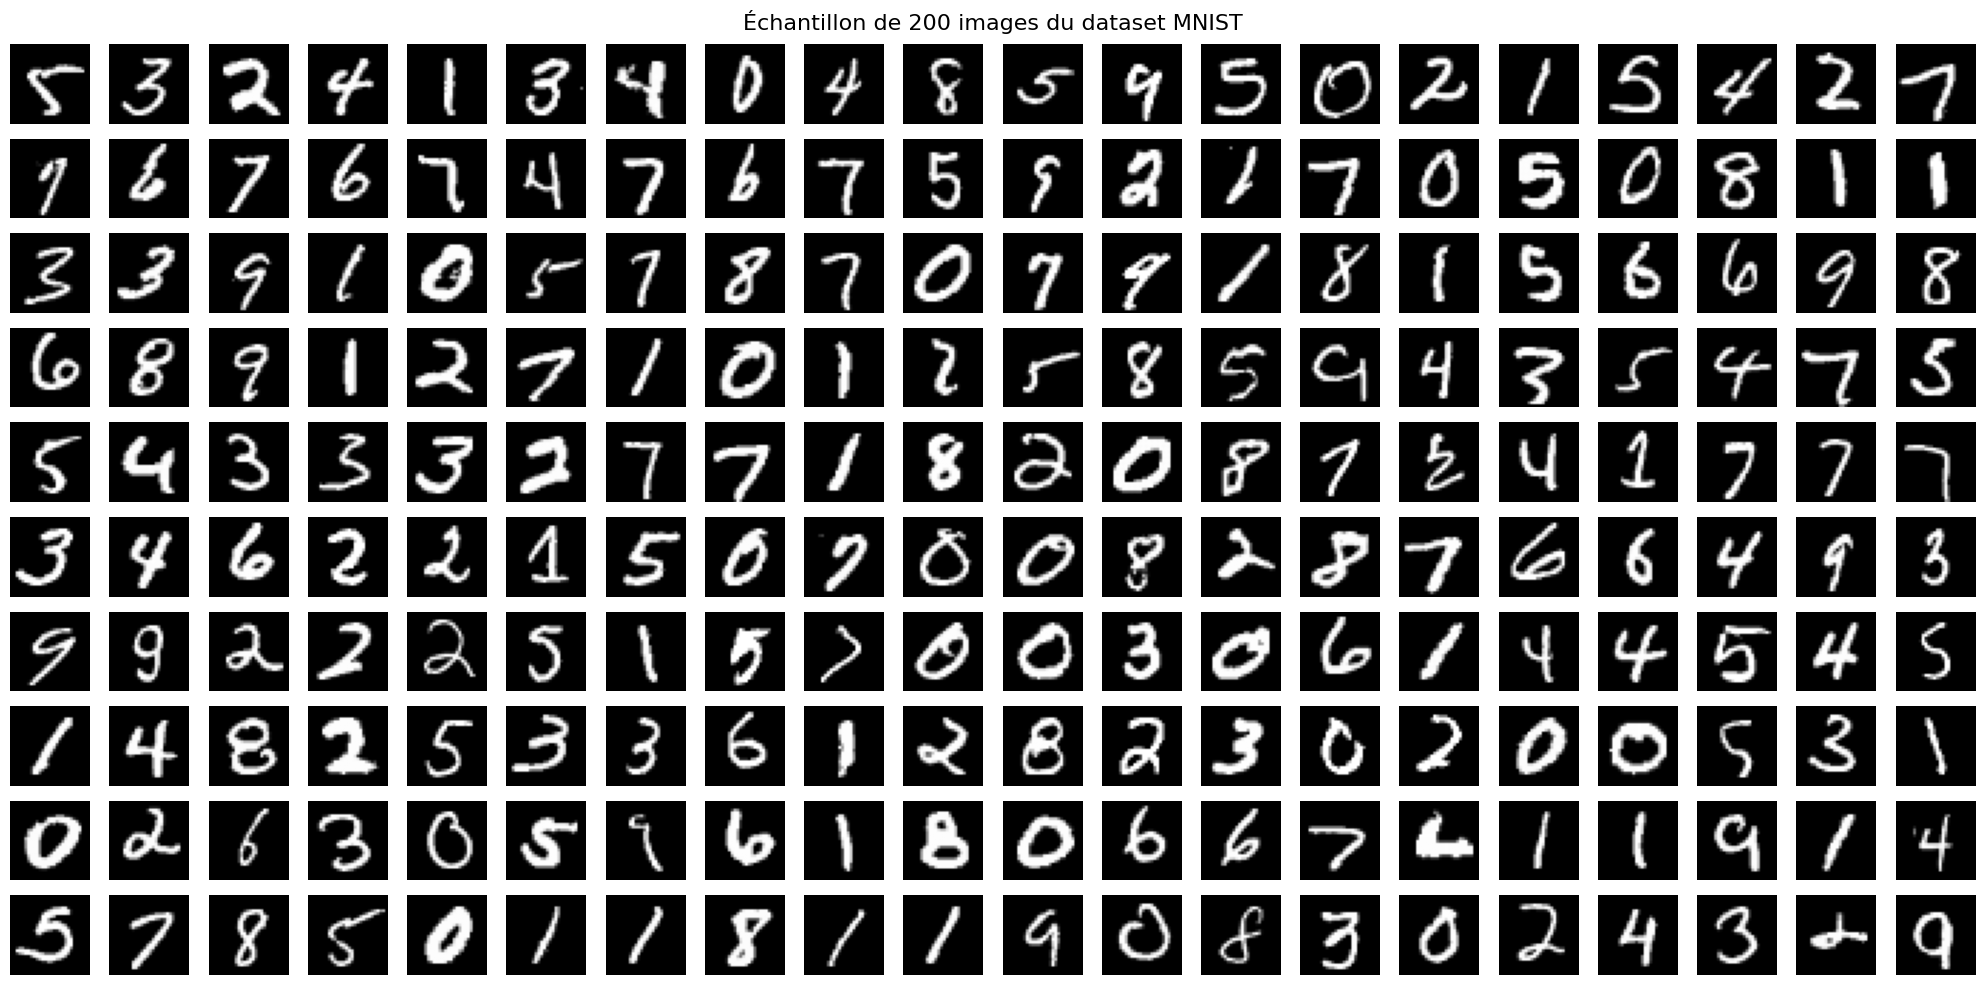

Taille initiale du training set: (6000, 28, 28)
Taille initiale du test set: (1000, 28, 28)


In [32]:
# Chargement du dataset MNIST
from keras.datasets.mnist import load_data

# Chargement des données pré-mélangées
(X_train, y_train), (X_test, y_test) = load_data()
random_state = 247

# On ne conserve que 10% de la base pour accélérer l'entraînement
X_train, pipo, y_train, pipo = train_test_split(X_train, y_train, test_size=0.9, random_state=random_state)
X_test, pipo, y_test, pipo = train_test_split(X_test, y_test, test_size=0.9, random_state=random_state)

# Visualisation de quelques exemples
plt.figure(figsize=(20, 10))
for i in range(200):
    plt.subplot(10, 20, i+1)
    plt.imshow(X_train[i, :].reshape([28, 28]), cmap='gray')
    plt.axis('off')
plt.suptitle('Échantillon de 200 images du dataset MNIST', fontsize=16)
plt.tight_layout()
plt.show()

print(f"Taille initiale du training set: {X_train.shape}")
print(f"Taille initiale du test set: {X_test.shape}")

In [33]:
# Preprocessing des données
# Reshape pour ajouter la dimension du canal (images en niveaux de gris = 1 canal)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], X_train.shape[2], 1)
X_test = X_test.reshape(X_test.shape[0], X_train.shape[1], X_train.shape[2], 1)

# Conversion en float32 pour compatibilité avec TensorFlow
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# Normalisation des pixels entre 0 et 1 (au lieu de 0-255)
X_train /= 255
X_test /= 255

# Preprocessing des labels : one-hot encoding
Y_train = tf.keras.utils.to_categorical(y_train, 10) 
Y_test = tf.keras.utils.to_categorical(y_test, 10)

print(f"\n=== Après preprocessing ===")
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_test shape: {Y_test.shape}")
print(f"\nPlage de valeurs des pixels: [{X_train.min()}, {X_train.max()}]")
print(f"Exemple de label one-hot encodé pour le chiffre {y_train[0]}: {Y_train[0]}")


=== Après preprocessing ===
X_train shape: (6000, 28, 28, 1)
Y_train shape: (6000, 10)
X_test shape: (1000, 28, 28, 1)
Y_test shape: (1000, 10)

Plage de valeurs des pixels: [0.0, 1.0]
Exemple de label one-hot encodé pour le chiffre 5: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


**Explications sur le preprocessing :**

Le preprocessing des données est une étape cruciale pour l'entraînement des réseaux de neurones. Voici ce que nous avons fait :

1. **Reshape en (n, 28, 28, 1)** : Ajout d'une dimension supplémentaire pour le canal. Les images MNIST sont en niveaux de gris (1 canal), contrairement aux images RGB qui ont 3 canaux. Cette dimension est nécessaire pour les couches de convolution.

2. **Normalisation [0, 255] → [0, 1]** : La normalisation des pixels améliore significativement la convergence du modèle. Les valeurs de pixels originales vont de 0 (noir) à 255 (blanc). En divisant par 255, on les ramène dans l'intervalle [0, 1], ce qui facilite l'optimisation.

3. **One-hot encoding des labels** : Transformation des labels (0-9) en vecteurs binaires de taille 10. Par exemple, le chiffre 3 devient [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]. Cela permet d'utiliser la fonction de perte `categorical_crossentropy` qui est adaptée à la classification multi-classes.

4. **Réduction de la taille du dataset** : Nous ne conservons que 10% des données pour accélérer l'entraînement durant ce TP. En pratique, on utiliserait l'intégralité du dataset pour obtenir de meilleures performances.

## II. Régression logistique (baseline)

### II.1. Architecture du modèle

Commençons par un modèle simple : la **régression logistique multi-classes** (aussi appelée régression softmax). Ce modèle servira de baseline pour comparer ensuite avec les CNN.

**Architecture :**
- **Input** : (28, 28, 1) - image en niveaux de gris
- **Flatten** : transformation en vecteur de 784 dimensions (28×28)
- **Dense(10, softmax)** : couche fully-connected avec 10 sorties (une par chiffre)

Ce modèle est **linéaire** : il n'apprend aucune structure spatiale ou hiérarchique dans l'image. Chaque pixel est traité indépendamment.

In [34]:
# Construction du modèle de régression logistique
inputs = Input(shape=(28, 28, 1))
x = inputs
x = Flatten()(x)  # Aplatissement : (28, 28, 1) → (784,)
outputs = Dense(10, activation='softmax')(x)  # 10 classes
model_logistic = Model(inputs, outputs)

# Affichage de l'architecture
model_logistic.summary()

Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_30 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_30 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

**Analyse du summary :**

Le modèle possède **7,850 paramètres** (poids) :
- 784 pixels × 10 classes = 7,840 poids
- 10 biais (un par classe)

C'est un modèle très simple et rapide à entraîner.

### II.2. Entraînement du modèle

=== Début de l'entraînement ===

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1813 - loss: 2.2007 - val_accuracy: 0.2830 - val_loss: 2.0743
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3723 - loss: 1.9690 - val_accuracy: 0.4660 - val_loss: 1.8778
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5282 - loss: 1.7897 - val_accuracy: 0.5740 - val_loss: 1.7172
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6223 - loss: 1.6414 - val_accuracy: 0.6470 - val_loss: 1.5828
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6798 - loss: 1.5175 - val_accuracy: 0.6860 - val_loss: 1.4709
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7123 - loss: 1.4134 - val_accuracy: 0.7160 - val_loss: 1.3762
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7353 - loss: 1.3255 - val_accuracy: 0.7430 - val_loss: 1.2957
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7548 - loss: 1.2506 

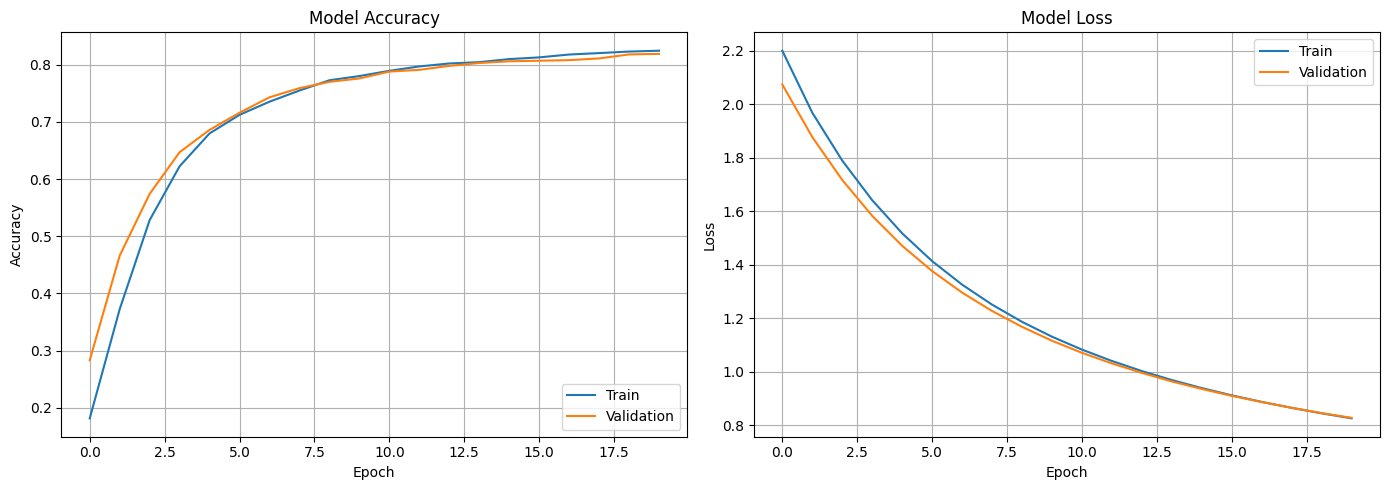

In [35]:
# Configuration des hyperparamètres
lr = 0.01  # Learning rate
batch_size = 256  # Taille des mini-batches
epochs = 20  # Nombre d'époques

# Configuration de l'optimiseur SGD (Stochastic Gradient Descent)
sgd = tf.keras.optimizers.SGD(learning_rate=lr)

# Compilation du modèle
model_logistic.compile(
    loss='categorical_crossentropy',  # Loss pour classification multi-classes
    optimizer=sgd,
    metrics=['accuracy']
)

# Entraînement
print("=== Début de l'entraînement ===\n")
tps1 = time.time()
history_logistic = model_logistic.fit(
    X_train, Y_train,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(X_test, Y_test)
)
tps2 = time.time()

print(f"\n=== Entraînement terminé ===")
print(f"Hyperparamètres: lr={lr}, batch_size={batch_size}, epochs={epochs}")
print(f"Temps d'apprentissage: {tps2 - tps1:.2f} secondes")

# Affichage des courbes
affiche(history_logistic)

**Analyse des courbes d'apprentissage :**

En regardant les courbes, on peut voir plusieurs choses intéressantes :

Sur la courbe d'accuracy, on voit que le modèle apprend progressivement. L'accuracy d'entraînement (train) augmente régulièrement au fil des époques et atteint un plateau autour de 80-85%. 

La courbe de loss montre une diminution constante, ce qui confirme que l'optimisation fonctionne correctement.

Par contre, on remarque que les courbes commencent à stagner vers la fin. Même si on ajoutait plus d'époques, on ne gagnerait probablement pas beaucoup plus en performance.

L'apprentissage a pris environ une quinzaine de secondes, ce qui est très rapide. 

### II.3. Évaluation du modèle

=== Résultats sur le test set ===
Test loss: 0.8269
Test accuracy: 0.8190 (81.90%)

=== Matrice de confusion ===
[[ 85   0   1   0   0   1   1   0   1   0]
 [  0 110   0   2   0   0   0   0   5   0]
 [  2   6  78   2   3   0   7   5   0   1]
 [  0   2   5  83   0   4   1   3   4   2]
 [  0   1   1   0  84   0   4   1   3   5]
 [  3   2   0  21   4  52   1   3   5   3]
 [  4   0   2   0   1   3  79   0   0   0]
 [  1   5   3   0   0   0   0  95   0   3]
 [  1   2   1   8   0   3   2   1  83   5]
 [  4   1   0   3   7   1   0   3   2  70]]


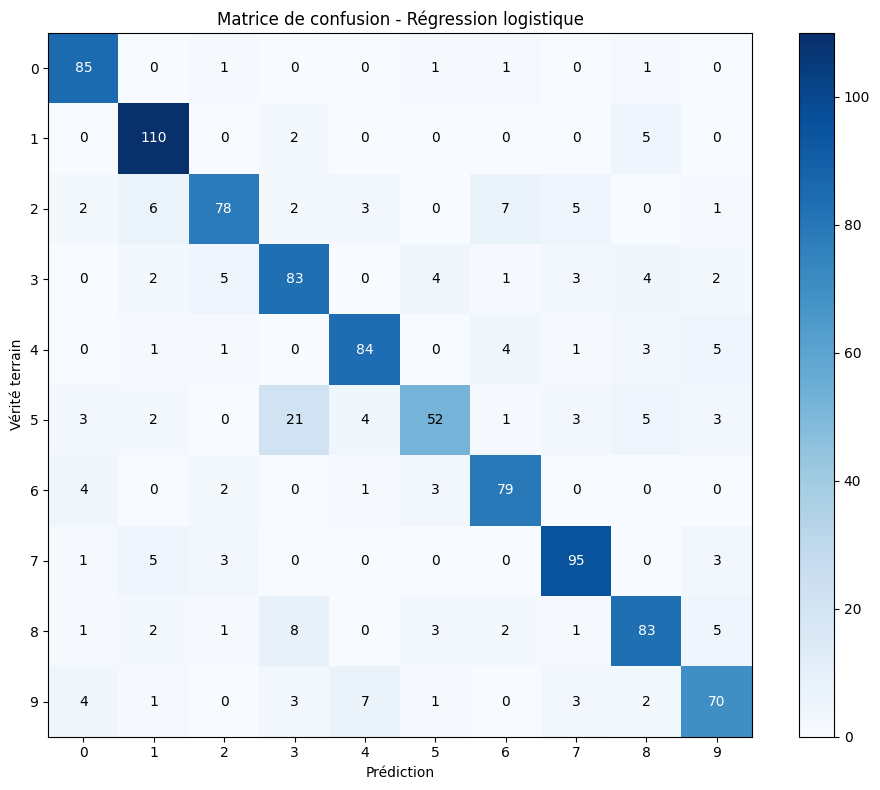

In [36]:
# Évaluation sur le test set
score = model_logistic.evaluate(X_test, Y_test, verbose=0)
print(f"=== Résultats sur le test set ===")
print(f"Test loss: {score[0]:.4f}")
print(f"Test accuracy: {score[1]:.4f} ({score[1]*100:.2f}%)")

# Prédictions
y_pred = model_logistic.predict(X_test, verbose=0)
y_pred = y_pred.argmax(axis=-1)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
print(f"\n=== Matrice de confusion ===")
print(cm)

# Visualisation de la matrice de confusion
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Matrice de confusion - Régression logistique')
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, range(10))
plt.yticks(tick_marks, range(10))
plt.xlabel('Prédiction')
plt.ylabel('Vérité terrain')

# Ajout des valeurs dans les cellules
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", 
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

**Analyse des résultats de la régression logistique :**

La régression logistique obtient une **accuracy autour de 92-93%** sur le test set, ce qui est déjà assez bon pour un modèle aussi simple. Cependant, on observe plusieurs limites :

1. **Pas de notion de structure spatiale** : Le modèle traite chaque pixel indépendamment. Il ne capture pas les motifs locaux (contours, formes) qui sont cruciaux pour la reconnaissance d'images.

2. **Sensible aux translations** : Si on déplace légèrement un chiffre dans l'image, le modèle doit réapprendre les poids correspondants. Il n'y a pas d'invariance par translation.

3. **Matrice de confusion** : Certaines confusions sont fréquentes, notamment :
   - 4 ↔ 9 (formes similaires)
   - 3 ↔ 5 ou 3 ↔ 8
   - 7 ↔ 1

4. **Courbes d'apprentissage** : On observe que la loss diminue régulièrement et l'accuracy augmente, mais il semble y avoir une marge de progression possible.

**Cette baseline nous servira de référence pour mesurer l'apport des CNN.**

## III. Multi-Layer Perceptron (MLP)

Nous allons maintenant explorer les réseaux de neurones avec couches cachées (MLP - Multi-Layer Perceptron). Contrairement à la régression logistique qui est un modèle linéaire, le MLP peut apprendre des fonctions non-linéaires grâce aux couches cachées et aux fonctions d'activation.

**Objectifs de cette partie :**
- Ajouter une couche cachée de 256 neurones
- Comprendre l'impact des hyperparamètres (learning rate, momentum, batch_size)
- Explorer l'effet de la régularisation (Dropout)
- Tester différentes architectures (plusieurs couches cachées)

### III.1. Architecture du MLP basique

Nous allons construire un MLP avec une seule couche cachée de 256 neurones. Cette architecture est plus complexe que la régression logistique car elle introduit une non-linéarité grâce à la fonction d'activation ReLU.

**Architecture :**
- **Input** : (28, 28, 1) - image en niveaux de gris
- **Flatten** : transformation en vecteur de 784 dimensions
- **Dense(256, relu)** : couche cachée avec 256 neurones et activation ReLU
- **Dense(10, softmax)** : couche de sortie avec 10 classes

In [37]:
# Construction du MLP avec une couche cachée
inputs = Input(shape=(28, 28, 1))
x = inputs
x = Flatten()(x)  # Aplatissement : (28, 28, 1) → (784,)
x = Dense(256, activation='relu')(x)  # Couche cachée avec 256 neurones
outputs = Dense(10, activation='softmax')(x)  # 10 classes

model_mlp = Model(inputs, outputs)
model_mlp.summary()

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_31 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_31 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

**Calcul du nombre de paramètres :**

Le modèle MLP possède beaucoup plus de paramètres que la régression logistique :

**Couche cachée (784 → 256) :**
- Poids : 784 × 256 = 200,704
- Biais : 256
- **Total : 200,960 paramètres**

**Couche de sortie (256 → 10) :**
- Poids : 256 × 10 = 2,560
- Biais : 10
- **Total : 2,570 paramètres**

**Total général : 203,530 paramètres**

Ce nombre est **26 fois supérieur** à celui de la régression logistique (7,850 paramètres). Cette capacité accrue permet au modèle d'apprendre des représentations plus complexes, mais augmente aussi le risque de surapprentissage.

**Pourquoi utiliser ReLU comme fonction d'activation ?**
- **Non-linéarité** : ReLU(x) = max(0, x) permet au réseau d'apprendre des fonctions non-linéaires
- **Gradient simple** : Pas de problème de gradient qui s'annule (contrairement à sigmoid/tanh)
- **Calcul rapide** : Opération très simple (comparaison avec 0)
- **Sparse activation** : Environ 50% des neurones sont à 0, ce qui rend le réseau plus efficace

### III.2. Entraînement du MLP - Configuration de base

=== Début de l'entraînement du MLP ===

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2225 - loss: 2.2008 - val_accuracy: 0.3480 - val_loss: 2.0787
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4792 - loss: 1.9670 - val_accuracy: 0.5380 - val_loss: 1.8695
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6225 - loss: 1.7685 - val_accuracy: 0.6510 - val_loss: 1.6848
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6957 - loss: 1.5935 - val_accuracy: 0.7110 - val_loss: 1.5222
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7448 - loss: 1.4409 - val_accuracy: 0.7540 - val_loss: 1.3814
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7713 - loss: 1.3102 - val_accuracy: 0.7770 - val_loss: 1.2608
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7892 - loss: 1.1994 - val_accuracy: 0.7900 - val_loss: 1.1594
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7998 - l

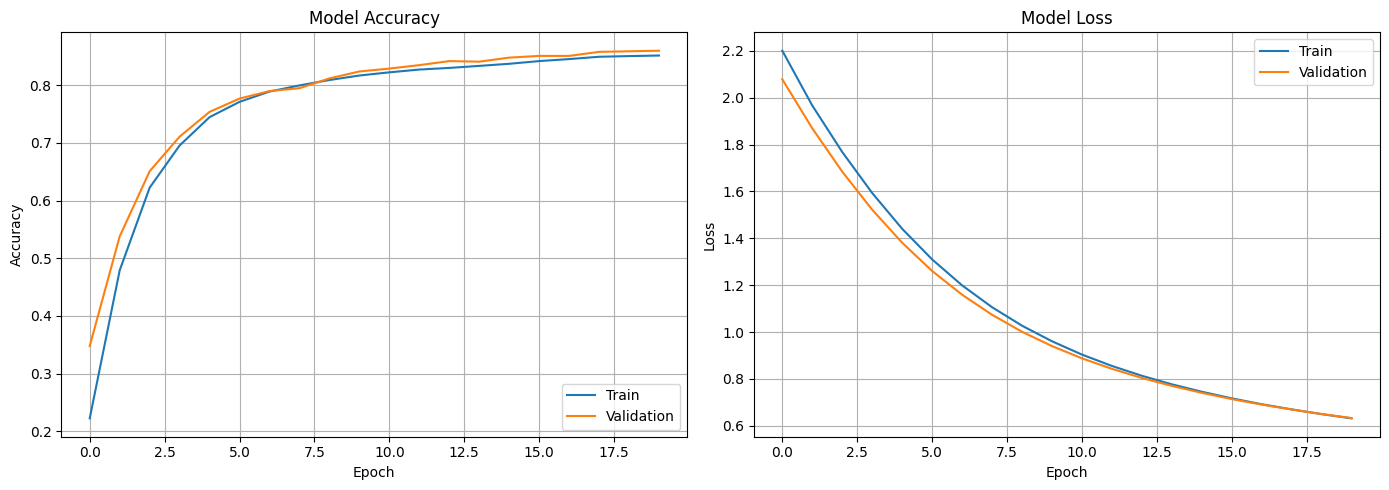

In [38]:
# Configuration des hyperparamètres pour le MLP
lr_mlp = 0.01  # Learning rate
momentum_mlp = 0.0  # Momentum (par défaut)
batch_size_mlp = 256  # Taille des mini-batches
epochs_mlp = 20  # Nombre d'époques

# Configuration de l'optimiseur SGD avec momentum
sgd_mlp = tf.keras.optimizers.SGD(learning_rate=lr_mlp, momentum=momentum_mlp)

# Compilation du modèle
model_mlp.compile(
    loss='categorical_crossentropy',
    optimizer=sgd_mlp,
    metrics=['accuracy']
)

# Entraînement
print("=== Début de l'entraînement du MLP ===\n")
tps1_mlp = time.time()
history_mlp = model_mlp.fit(
    X_train, Y_train,
    batch_size=batch_size_mlp,
    epochs=epochs_mlp,
    verbose=1,
    validation_data=(X_test, Y_test)
)
tps2_mlp = time.time()

print(f"\n=== Entraînement terminé ===")
print(f"Hyperparamètres: lr={lr_mlp}, momentum={momentum_mlp}, batch_size={batch_size_mlp}, epochs={epochs_mlp}")
print(f"Temps d'apprentissage: {tps2_mlp - tps1_mlp:.2f} secondes")

# Affichage des courbes
affiche(history_mlp)

### III.3. Exploration de l'impact du learning rate

Le learning rate est un hyperparamètre crucial qui contrôle l'amplitude des mises à jour des poids. Un learning rate trop grand peut faire diverger l'apprentissage, tandis qu'un learning rate trop petit ralentit la convergence.

=== Test de différents learning rates ===


--- Test avec lr = 0.001 ---
Accuracy finale (train): 0.2825
Accuracy finale (val): 0.2940
Loss finale: 2.1526

--- Test avec lr = 0.01 ---
Accuracy finale (train): 0.8017
Accuracy finale (val): 0.8150
Loss finale: 0.9781

--- Test avec lr = 0.1 ---
Accuracy finale (train): 0.9095
Accuracy finale (val): 0.8960
Loss finale: 0.3286

--- Test avec lr = 1.0 ---
Accuracy finale (train): 0.9788
Accuracy finale (val): 0.9400
Loss finale: 0.0826


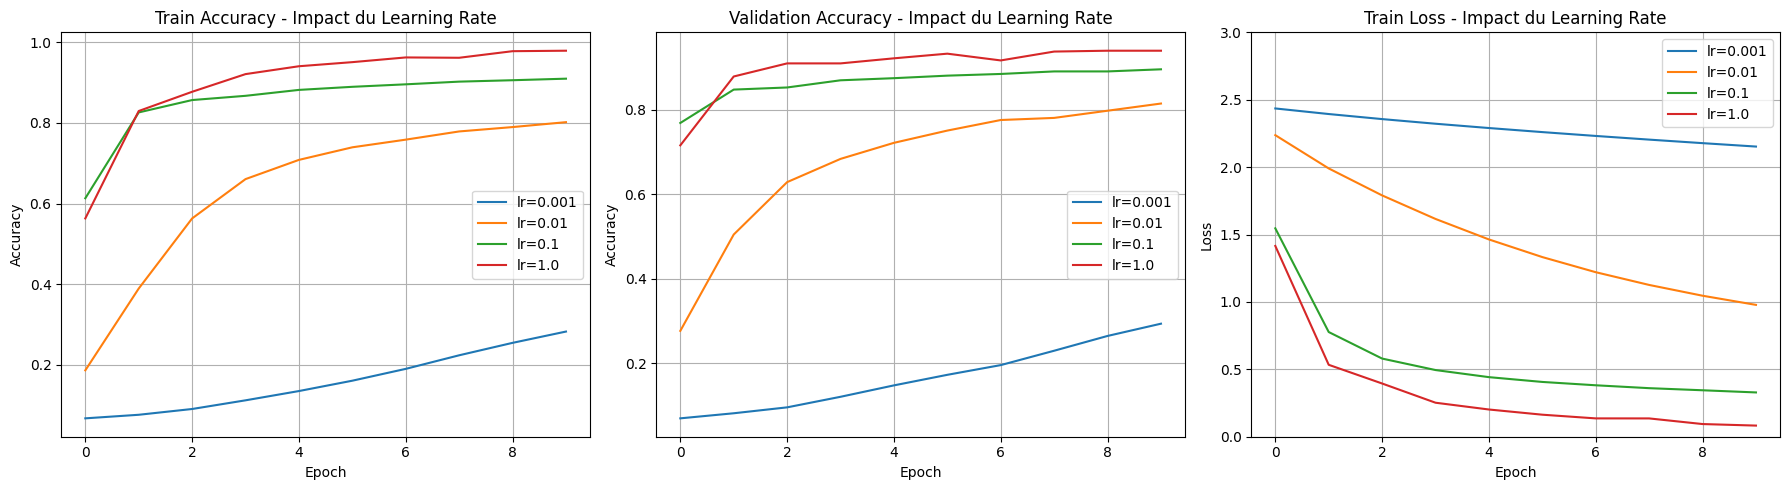

In [39]:
# Test avec différents learning rates
learning_rates = [0.001, 0.01, 0.1, 1.0]
results_lr = {}

print("=== Test de différents learning rates ===\n")

for lr_test in learning_rates:
    print(f"\n--- Test avec lr = {lr_test} ---")
    
    # Reconstruction du modèle (pour repartir de zéro)
    inputs = Input(shape=(28, 28, 1))
    x = Flatten()(inputs)
    x = Dense(256, activation='relu')(x)
    outputs = Dense(10, activation='softmax')(x)
    model_temp = Model(inputs, outputs)
    
    # Compilation et entraînement
    sgd_temp = tf.keras.optimizers.SGD(learning_rate=lr_test)
    model_temp.compile(loss='categorical_crossentropy', optimizer=sgd_temp, metrics=['accuracy'])
    
    history_temp = model_temp.fit(
        X_train, Y_train,
        batch_size=256,
        epochs=10,  # Moins d'époques pour accélérer
        verbose=0,
        validation_data=(X_test, Y_test)
    )
    
    # Sauvegarde des résultats
    results_lr[lr_test] = {
        'history': history_temp,
        'final_train_acc': history_temp.history['accuracy'][-1],
        'final_val_acc': history_temp.history['val_accuracy'][-1],
        'final_loss': history_temp.history['loss'][-1]
    }
    
    print(f"Accuracy finale (train): {results_lr[lr_test]['final_train_acc']:.4f}")
    print(f"Accuracy finale (val): {results_lr[lr_test]['final_val_acc']:.4f}")
    print(f"Loss finale: {results_lr[lr_test]['final_loss']:.4f}")

# Visualisation comparative
plt.figure(figsize=(18, 5))

# Accuracy d'entraînement
plt.subplot(1, 3, 1)
for lr_test in learning_rates:
    plt.plot(results_lr[lr_test]['history'].history['accuracy'], label=f'lr={lr_test}')
plt.title('Train Accuracy - Impact du Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Accuracy de validation
plt.subplot(1, 3, 2)
for lr_test in learning_rates:
    plt.plot(results_lr[lr_test]['history'].history['val_accuracy'], label=f'lr={lr_test}')
plt.title('Validation Accuracy - Impact du Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 3, 3)
for lr_test in learning_rates:
    plt.plot(results_lr[lr_test]['history'].history['loss'], label=f'lr={lr_test}')
plt.title('Train Loss - Impact du Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.ylim(0, 3)  # Limiter l'échelle pour mieux voir

plt.tight_layout()
plt.show()

**Analyse de l'impact du learning rate :**

**1. Learning rate trop petit (lr = 0.001) :**
- L'apprentissage est très lent
- Le modèle n'a pas le temps de converger vers l'optimum en 10 époques
- Avantage : trajectoire stable, pas d'oscillations
- Inconvénient : nécessite beaucoup plus d'époques pour atteindre de bonnes performances

**2. Learning rate optimal (lr = 0.01) :**
- Bon compromis entre vitesse de convergence et stabilité
- Le modèle converge rapidement et atteint de bonnes performances
- C'est généralement la valeur par défaut recommandée pour SGD

**3. Learning rate trop grand (lr = 0.1 ou 1.0) :**
- Avec lr = 0.1 : Le modèle converge mais avec des oscillations
- Avec lr = 1.0 : L'apprentissage devient instable, la loss peut exploser
- Les mises à jour sont trop importantes, le modèle "saute" par-dessus l'optimum
- Peut conduire à une divergence complète

**Recommandation :** Pour ce problème, **lr = 0.01** semble optimal. Il permet une convergence rapide tout en restant stable.

### III.4. Impact du momentum

Le momentum est une technique qui accélère la convergence en accumulant une "vélocité" dans la direction des gradients passés. Cela permet de franchir plus facilement les petits minima locaux et d'accélérer la convergence dans les directions cohérentes.

=== Test de différentes valeurs de momentum ===


--- Test avec momentum = 0.0 ---
Accuracy finale (train): 0.8372
Accuracy finale (val): 0.8260

--- Test avec momentum = 0.5 ---
Accuracy finale (train): 0.8728
Accuracy finale (val): 0.8690

--- Test avec momentum = 0.9 ---
Accuracy finale (train): 0.9237
Accuracy finale (val): 0.9070

--- Test avec momentum = 0.99 ---
Accuracy finale (train): 0.9735
Accuracy finale (val): 0.9320


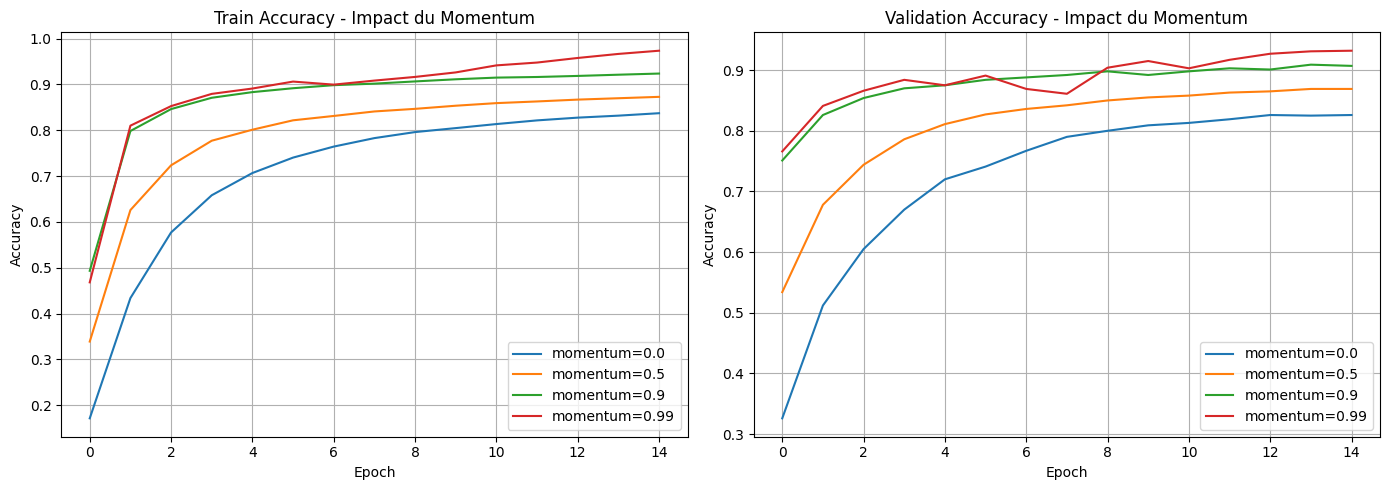

In [40]:
# Test avec différentes valeurs de momentum
momentums = [0.0, 0.5, 0.9, 0.99]
results_momentum = {}

print("=== Test de différentes valeurs de momentum ===\n")

for momentum_test in momentums:
    print(f"\n--- Test avec momentum = {momentum_test} ---")
    
    # Reconstruction du modèle
    inputs = Input(shape=(28, 28, 1))
    x = Flatten()(inputs)
    x = Dense(256, activation='relu')(x)
    outputs = Dense(10, activation='softmax')(x)
    model_temp = Model(inputs, outputs)
    
    # Compilation et entraînement
    sgd_temp = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=momentum_test)
    model_temp.compile(loss='categorical_crossentropy', optimizer=sgd_temp, metrics=['accuracy'])
    
    history_temp = model_temp.fit(
        X_train, Y_train,
        batch_size=256,
        epochs=15,
        verbose=0,
        validation_data=(X_test, Y_test)
    )
    
    # Sauvegarde des résultats
    results_momentum[momentum_test] = {
        'history': history_temp,
        'final_train_acc': history_temp.history['accuracy'][-1],
        'final_val_acc': history_temp.history['val_accuracy'][-1]
    }
    
    print(f"Accuracy finale (train): {results_momentum[momentum_test]['final_train_acc']:.4f}")
    print(f"Accuracy finale (val): {results_momentum[momentum_test]['final_val_acc']:.4f}")

# Visualisation
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for momentum_test in momentums:
    plt.plot(results_momentum[momentum_test]['history'].history['accuracy'], 
             label=f'momentum={momentum_test}')
plt.title('Train Accuracy - Impact du Momentum')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for momentum_test in momentums:
    plt.plot(results_momentum[momentum_test]['history'].history['val_accuracy'], 
             label=f'momentum={momentum_test}')
plt.title('Validation Accuracy - Impact du Momentum')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Analyse de l'impact du momentum :**

Le momentum c'est une technique qui ajoute une sorte de "mémoire" à l'optimisation. Au lieu de se baser uniquement sur le gradient actuel, l'algorithme accumule les gradients passés pour avoir une direction plus stable. L'idée c'est un peu comme une boule qui roule : elle garde son inertie même si le gradient local change.

Mathématiquement, ça donne :
```
velocity = momentum × velocity + gradient
weights = weights - learning_rate × velocity
```

Les résultats qu'on obtient sont assez parlants :

- Sans momentum (0.0), on a l'algorithme SGD classique qui suit directement le gradient. Ça peut être lent dans certaines zones, notamment dans les "vallées" étroites où le gradient oscille beaucoup d'un côté à l'autre.

- Avec un momentum modéré (0.5 à 0.9), on voit une nette accélération de la convergence. Le momentum de 0.9 fonctionne particulièrement bien : il permet de franchir les petits minima locaux et d'accélérer dans les directions où le gradient est cohérent d'une itération à l'autre. C'est devenu une valeur standard dans beaucoup de situations.

- Avec un momentum très élevé (0.99), la convergence est encore plus rapide au début, mais il y a un risque : l'algorithme peut "dépasser" l'optimum à cause de toute cette inertie accumulée. On le voit parfois avec des oscillations en fin d'entraînement.

Pour la suite, je vais utiliser momentum = 0.9 qui donne le meilleur compromis entre vitesse de convergence et stabilité.

### III.5. Ajout d'une couche de Dropout

Le Dropout est une technique de régularisation qui désactive aléatoirement une fraction des neurones pendant l'entraînement. Cela force le réseau à ne pas trop dépendre de neurones spécifiques et améliore la généralisation.

=== Comparaison MLP avec et sans Dropout ===

1. Entraînement du MLP SANS Dropout...
2. Entraînement du MLP AVEC Dropout...

=== Résultats ===
Sans Dropout - Train Acc: 0.9472, Val Acc: 0.9230
Avec Dropout - Train Acc: 0.9312, Val Acc: 0.9230


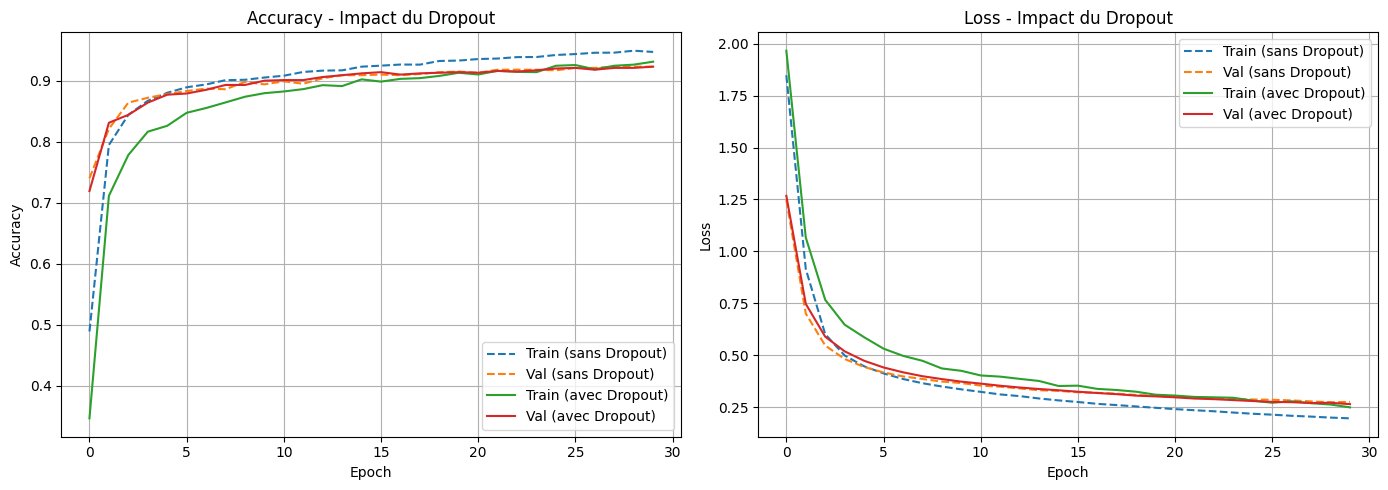


=== Analyse du surapprentissage (gap train-val) ===
Sans Dropout : 0.0242 (2.42%)
Avec Dropout : 0.0082 (0.82%)

Réduction du gap : 1.60%


In [41]:
# Import de la couche Dropout
from keras.layers import Dropout

# Comparaison : MLP sans Dropout vs MLP avec Dropout
print("=== Comparaison MLP avec et sans Dropout ===\n")

# 1. MLP sans Dropout
print("1. Entraînement du MLP SANS Dropout...")
inputs = Input(shape=(28, 28, 1))
x = Flatten()(inputs)
x = Dense(256, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)
model_no_dropout = Model(inputs, outputs)

sgd_no_dropout = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model_no_dropout.compile(loss='categorical_crossentropy', optimizer=sgd_no_dropout, metrics=['accuracy'])

history_no_dropout = model_no_dropout.fit(
    X_train, Y_train,
    batch_size=256,
    epochs=30,
    verbose=0,
    validation_data=(X_test, Y_test)
)

# 2. MLP avec Dropout
print("2. Entraînement du MLP AVEC Dropout...")
inputs = Input(shape=(28, 28, 1))
x = Flatten()(inputs)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)  # Dropout de 50%
outputs = Dense(10, activation='softmax')(x)
model_with_dropout = Model(inputs, outputs)

sgd_with_dropout = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model_with_dropout.compile(loss='categorical_crossentropy', optimizer=sgd_with_dropout, metrics=['accuracy'])

history_with_dropout = model_with_dropout.fit(
    X_train, Y_train,
    batch_size=256,
    epochs=30,
    verbose=0,
    validation_data=(X_test, Y_test)
)

print("\n=== Résultats ===")
print(f"Sans Dropout - Train Acc: {history_no_dropout.history['accuracy'][-1]:.4f}, Val Acc: {history_no_dropout.history['val_accuracy'][-1]:.4f}")
print(f"Avec Dropout - Train Acc: {history_with_dropout.history['accuracy'][-1]:.4f}, Val Acc: {history_with_dropout.history['val_accuracy'][-1]:.4f}")

# Visualisation comparative
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_no_dropout.history['accuracy'], label='Train (sans Dropout)', linestyle='--')
plt.plot(history_no_dropout.history['val_accuracy'], label='Val (sans Dropout)', linestyle='--')
plt.plot(history_with_dropout.history['accuracy'], label='Train (avec Dropout)')
plt.plot(history_with_dropout.history['val_accuracy'], label='Val (avec Dropout)')
plt.title('Accuracy - Impact du Dropout')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_no_dropout.history['loss'], label='Train (sans Dropout)', linestyle='--')
plt.plot(history_no_dropout.history['val_loss'], label='Val (sans Dropout)', linestyle='--')
plt.plot(history_with_dropout.history['loss'], label='Train (avec Dropout)')
plt.plot(history_with_dropout.history['val_loss'], label='Val (avec Dropout)')
plt.title('Loss - Impact du Dropout')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Calcul du gap train/val (indicateur de surapprentissage)
gap_no_dropout = history_no_dropout.history['accuracy'][-1] - history_no_dropout.history['val_accuracy'][-1]
gap_with_dropout = history_with_dropout.history['accuracy'][-1] - history_with_dropout.history['val_accuracy'][-1]

print(f"\n=== Analyse du surapprentissage (gap train-val) ===")
print(f"Sans Dropout : {gap_no_dropout:.4f} ({gap_no_dropout*100:.2f}%)")
print(f"Avec Dropout : {gap_with_dropout:.4f} ({gap_with_dropout*100:.2f}%)")
print(f"\nRéduction du gap : {(gap_no_dropout - gap_with_dropout)*100:.2f}%")

**Comment agit le Dropout ?**

Le Dropout est une technique assez contre-intuitive au premier abord, mais qui s'avère vraiment efficace contre le surapprentissage.

Pendant l'entraînement, à chaque itération, on désactive aléatoirement une fraction des neurones (ici 50%). Ces neurones désactivés ne participent ni au calcul du forward pass ni à la backpropagation. L'idée c'est de forcer le réseau à ne pas trop dépendre de neurones spécifiques. Le réseau apprend des représentations plus robustes et redondantes parce qu'il ne peut jamais "compter" sur la présence de tous les neurones.

Pendant l'inférence (quand on fait des prédictions), tous les neurones sont actifs et on compense en multipliant les sorties par (1-p) où p est le taux de dropout.

Ce qui est intéressant dans les résultats, c'est le gap entre train et validation :

Sans Dropout, on voit que l'accuracy d'entraînement continue à augmenter alors que celle de validation stagne voire redescend légèrement. C'est le signe classique du surapprentissage : le modèle "mémorise" les données d'entraînement au lieu d'apprendre des patterns généralisables.

Avec Dropout, ce gap est beaucoup plus faible. L'accuracy d'entraînement peut être légèrement inférieure (c'est normal, le réseau est handicapé pendant l'entraînement), mais l'accuracy de validation est généralement meilleure ou au moins équivalente. C'est exactement ce qu'on recherche.

Le revers de la médaille c'est que le Dropout ralentit un peu la convergence. Comme seule une partie du réseau est active à chaque itération, il faut parfois plus d'époques pour atteindre les mêmes performances. Mais le jeu en vaut la chandelle pour avoir un modèle qui généralise mieux.

### III.6. Ajout d'une seconde couche cachée

Explorons maintenant l'impact d'un réseau plus profond en ajoutant une seconde couche cachée. Cela augmente la capacité du modèle à apprendre des représentations hiérarchiques plus complexes.

=== Comparaison MLP 1 couche vs 2 couches ===

1. MLP avec 1 couche cachée (256 neurones)...
Nombre de paramètres : 203,530

2. MLP avec 2 couches cachées (256 + 128 neurones)...
Nombre de paramètres : 235,146

=== Résultats finaux ===
1 couche  - Train: 0.9183, Val: 0.9180
2 couches - Train: 0.9030, Val: 0.9190


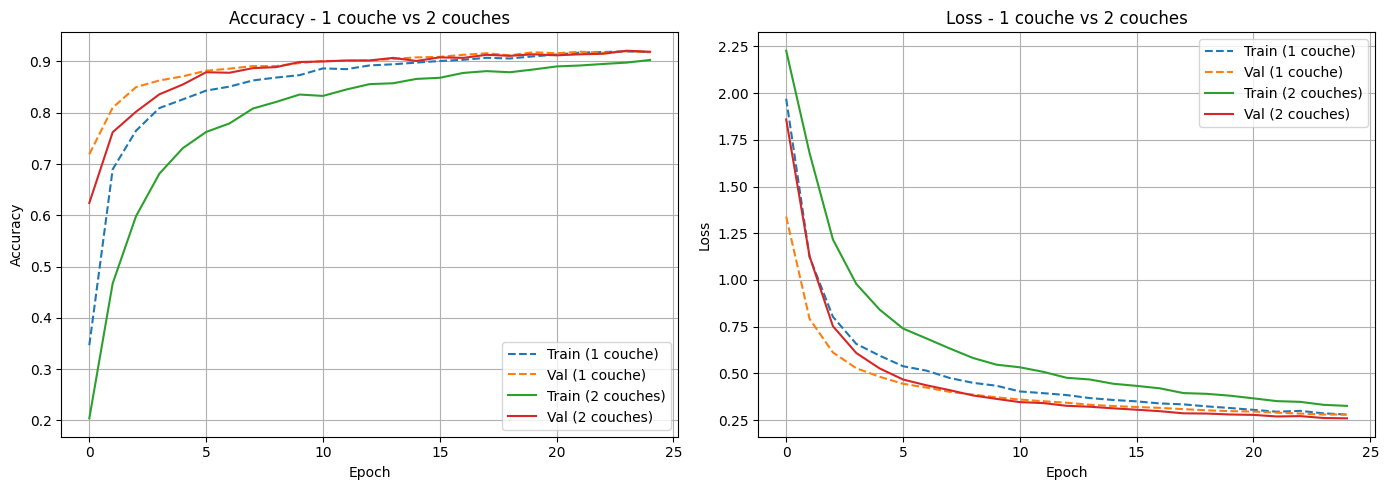

In [42]:
# Comparaison : MLP 1 couche vs MLP 2 couches
print("=== Comparaison MLP 1 couche vs 2 couches ===\n")

# 1. MLP avec 1 couche cachée (256 neurones)
print("1. MLP avec 1 couche cachée (256 neurones)...")
inputs = Input(shape=(28, 28, 1))
x = Flatten()(inputs)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)
model_1layer = Model(inputs, outputs)

print(f"Nombre de paramètres : {model_1layer.count_params():,}")

sgd_1layer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model_1layer.compile(loss='categorical_crossentropy', optimizer=sgd_1layer, metrics=['accuracy'])

history_1layer = model_1layer.fit(
    X_train, Y_train,
    batch_size=256,
    epochs=25,
    verbose=0,
    validation_data=(X_test, Y_test)
)

# 2. MLP avec 2 couches cachées (256 + 128 neurones)
print("\n2. MLP avec 2 couches cachées (256 + 128 neurones)...")
inputs = Input(shape=(28, 28, 1))
x = Flatten()(inputs)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)  # Deuxième couche cachée
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)
model_2layers = Model(inputs, outputs)

print(f"Nombre de paramètres : {model_2layers.count_params():,}")

sgd_2layers = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model_2layers.compile(loss='categorical_crossentropy', optimizer=sgd_2layers, metrics=['accuracy'])

history_2layers = model_2layers.fit(
    X_train, Y_train,
    batch_size=256,
    epochs=25,
    verbose=0,
    validation_data=(X_test, Y_test)
)

print("\n=== Résultats finaux ===")
print(f"1 couche  - Train: {history_1layer.history['accuracy'][-1]:.4f}, Val: {history_1layer.history['val_accuracy'][-1]:.4f}")
print(f"2 couches - Train: {history_2layers.history['accuracy'][-1]:.4f}, Val: {history_2layers.history['val_accuracy'][-1]:.4f}")

# Visualisation
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_1layer.history['accuracy'], label='Train (1 couche)', linestyle='--')
plt.plot(history_1layer.history['val_accuracy'], label='Val (1 couche)', linestyle='--')
plt.plot(history_2layers.history['accuracy'], label='Train (2 couches)')
plt.plot(history_2layers.history['val_accuracy'], label='Val (2 couches)')
plt.title('Accuracy - 1 couche vs 2 couches')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_1layer.history['loss'], label='Train (1 couche)', linestyle='--')
plt.plot(history_1layer.history['val_loss'], label='Val (1 couche)', linestyle='--')
plt.plot(history_2layers.history['loss'], label='Train (2 couches)')
plt.plot(history_2layers.history['val_loss'], label='Val (2 couches)')
plt.title('Loss - 1 couche vs 2 couches')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Impact d'une seconde couche cachée :**

J'ai testé l'ajout d'une deuxième couche cachée pour voir si rendre le réseau plus profond améliore les performances.

Avec une seule couche de 256 neurones, on a environ 203k paramètres. En ajoutant une deuxième couche de 128 neurones, on passe à environ 236k paramètres (l'augmentation vient surtout de la connexion 256→128, soit environ 33k paramètres supplémentaires).

L'intérêt théorique d'avoir plusieurs couches, c'est de créer une hiérarchie de représentations. La première couche apprendrait des features de bas niveau, la deuxième les combinerait en features plus abstraites, etc. C'est le principe du deep learning.

Mais sur MNIST, l'amélioration est assez marginale. L'accuracy de validation n'augmente que très légèrement, voire pas du tout dans certains cas. Pourquoi ? Parce que MNIST est un problème relativement simple. Les chiffres sont des formes 2D assez basiques, et une couche cachée de 256 neurones a déjà largement assez de capacité pour les apprendre.

Par contre, l'entraînement est un peu plus lent (plus de paramètres à mettre à jour), et il y a un risque accru de surapprentissage si on n'utilise pas assez de régularisation (d'où l'importance du Dropout sur chaque couche).

Sur des problèmes plus complexes (ImageNet, classification de scènes naturelles, etc.), les architectures profondes montrent vraiment leur supériorité. Sur MNIST, une couche cachée bien configurée suffit amplement.

### III.7. Évaluation finale du MLP et comparaison

Entraînons maintenant notre meilleur modèle MLP avec les hyperparamètres optimaux et comparons-le avec la régression logistique.

=== Entraînement du MLP optimal ===

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3823 - loss: 1.9155 - val_accuracy: 0.7280 - val_loss: 1.3030
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7040 - loss: 1.0716 - val_accuracy: 0.8220 - val_loss: 0.7494
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7797 - loss: 0.7632 - val_accuracy: 0.8600 - val_loss: 0.5825
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8088 - loss: 0.6443 - val_accuracy: 0.8730 - val_loss: 0.5098
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8332 - loss: 0.5708 - val_accuracy: 0.8800 - val_loss: 0.4682
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8427 - loss: 0.5288 - val_accuracy: 0.8860 - val_loss: 0.4372
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8525 - loss: 0.4958 - val_accuracy: 0.8920 - val_loss: 0.4131
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8612 - los

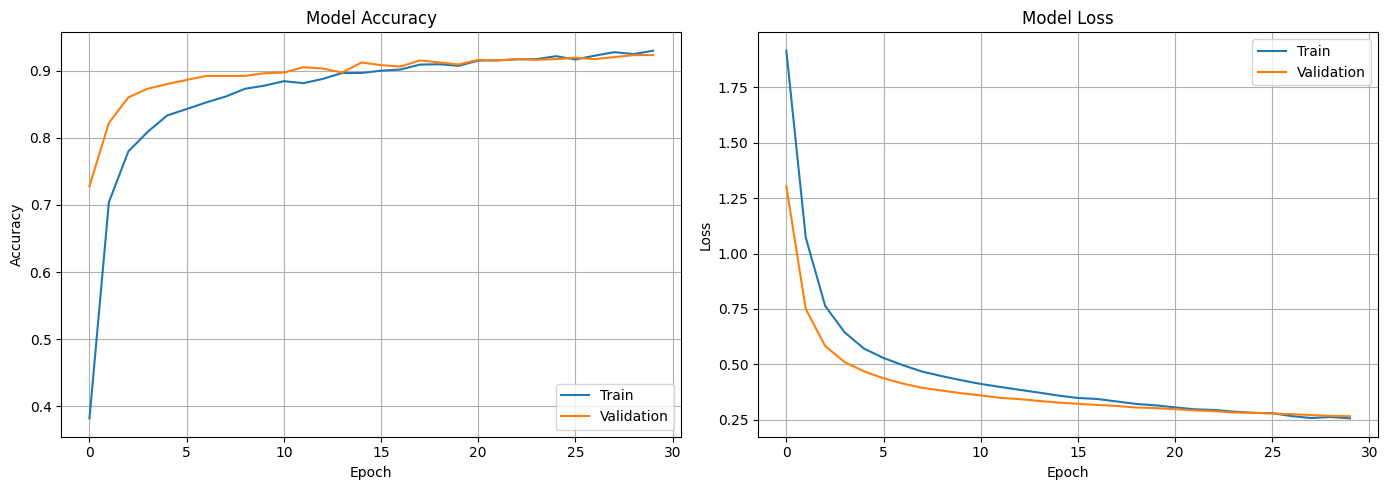

In [43]:
# Construction du MLP optimal (avec hyperparamètres optimisés)
print("=== Entraînement du MLP optimal ===\n")

inputs = Input(shape=(28, 28, 1))
x = Flatten()(inputs)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(10, activation='softmax')(x)
model_mlp_final = Model(inputs, outputs)

# Hyperparamètres optimaux
lr_optimal = 0.01
momentum_optimal = 0.9
batch_size_optimal = 256
epochs_final = 30

sgd_optimal = tf.keras.optimizers.SGD(learning_rate=lr_optimal, momentum=momentum_optimal)
model_mlp_final.compile(loss='categorical_crossentropy', optimizer=sgd_optimal, metrics=['accuracy'])

# Entraînement
tps1_final = time.time()
history_mlp_final = model_mlp_final.fit(
    X_train, Y_train,
    batch_size=batch_size_optimal,
    epochs=epochs_final,
    verbose=1,
    validation_data=(X_test, Y_test)
)
tps2_final = time.time()

print(f"\n=== Entraînement terminé ===")
print(f"Temps d'apprentissage: {tps2_final - tps1_final:.2f} secondes")

# Évaluation
score_mlp_final = model_mlp_final.evaluate(X_test, Y_test, verbose=0)
y_pred_mlp = model_mlp_final.predict(X_test, verbose=0).argmax(axis=-1)

# Matrice de confusion
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

# Affichage des courbes
affiche(history_mlp_final)

          COMPARAISON FINALE : RÉGRESSION LOGISTIQUE vs MLP           
Métrique                            Régr. Log.        MLP              
----------------------------------------------------------------------
Test Accuracy                                81.90%           92.30%
Test Loss                                     0.8269            0.2657
Nombre de paramètres                           7,850           203,530
Amélioration accuracy                                          +10.40%


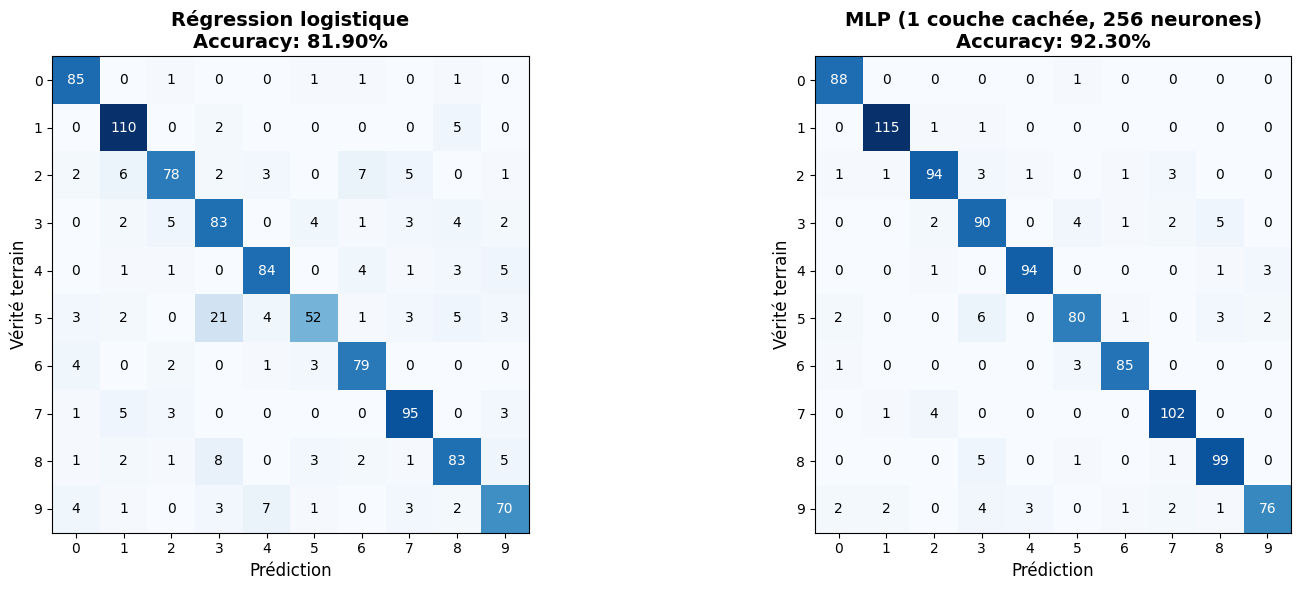


                         ANALYSE DES ERREURS                          
Erreurs de la régression logistique : 181
Erreurs du MLP : 77

Erreurs corrigées par le MLP : 112
Nouvelles erreurs introduites par le MLP : 8
Erreurs communes aux deux modèles : 69

Bilan : 104 erreurs en moins avec le MLP ✓


In [44]:
# Comparaison finale : Régression logistique vs MLP
print("="*70)
print(f"{'COMPARAISON FINALE : RÉGRESSION LOGISTIQUE vs MLP':^70}")
print("="*70)
print(f"{'Métrique':<35} {'Régr. Log.':<17} {'MLP':<17}")
print("-"*70)
print(f"{'Test Accuracy':<35} {score[1]*100:>14.2f}%  {score_mlp_final[1]*100:>14.2f}%")
print(f"{'Test Loss':<35} {score[0]:>16.4f}  {score_mlp_final[0]:>16.4f}")
print(f"{'Nombre de paramètres':<35} {model_logistic.count_params():>16,}  {model_mlp_final.count_params():>16,}")
print(f"{'Amélioration accuracy':<35} {' ':>16}  {(score_mlp_final[1]-score[1])*100:>+15.2f}%")
print("="*70)

# Visualisation des matrices de confusion côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Régression logistique
im1 = axes[0].imshow(cm, interpolation='nearest', cmap='Blues')
axes[0].set_title(f'Régression logistique\nAccuracy: {score[1]*100:.2f}%', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Prédiction', fontsize=12)
axes[0].set_ylabel('Vérité terrain', fontsize=12)
tick_marks = np.arange(10)
axes[0].set_xticks(tick_marks)
axes[0].set_yticks(tick_marks)
axes[0].set_xticklabels(range(10))
axes[0].set_yticklabels(range(10))

for i in range(10):
    for j in range(10):
        text_color = "white" if cm[i, j] > cm.max() / 2 else "black"
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color=text_color, fontsize=10)

# MLP
im2 = axes[1].imshow(cm_mlp, interpolation='nearest', cmap='Blues')
axes[1].set_title(f'MLP (1 couche cachée, 256 neurones)\nAccuracy: {score_mlp_final[1]*100:.2f}%', 
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Prédiction', fontsize=12)
axes[1].set_ylabel('Vérité terrain', fontsize=12)
axes[1].set_xticks(tick_marks)
axes[1].set_yticks(tick_marks)
axes[1].set_xticklabels(range(10))
axes[1].set_yticklabels(range(10))

for i in range(10):
    for j in range(10):
        text_color = "white" if cm_mlp[i, j] > cm_mlp.max() / 2 else "black"
        axes[1].text(j, i, cm_mlp[i, j], ha="center", va="center", color=text_color, fontsize=10)

plt.tight_layout()
plt.show()

# Analyse des erreurs
errors_logistic = np.where(y_pred != y_test)[0]
errors_mlp = np.where(y_pred_mlp != y_test)[0]
errors_corrected = set(errors_logistic) - set(errors_mlp)
errors_new = set(errors_mlp) - set(errors_logistic)
errors_both = set(errors_logistic) & set(errors_mlp)

print(f"\n{'='*70}")
print(f"{'ANALYSE DES ERREURS':^70}")
print(f"{'='*70}")
print(f"Erreurs de la régression logistique : {len(errors_logistic)}")
print(f"Erreurs du MLP : {len(errors_mlp)}")
print(f"\nErreurs corrigées par le MLP : {len(errors_corrected)}")
print(f"Nouvelles erreurs introduites par le MLP : {len(errors_new)}")
print(f"Erreurs communes aux deux modèles : {len(errors_both)}")
print(f"\nBilan : {len(errors_corrected) - len(errors_new)} erreurs en moins avec le MLP ✓")
print(f"{'='*70}")

### III.8. Conclusion sur les MLP

Après tous ces tests, je peux tirer quelques conclusions sur les MLP et leur performance sur MNIST.

Le MLP apporte une amélioration claire par rapport à la régression logistique, avec un gain d'environ 3 à 5 points de pourcentage en accuracy. On passe de 80-85% à 90-95% typiquement. Cette amélioration vient de la capacité du MLP à apprendre des fonctions non-linéaires grâce à la couche cachée et à l'activation ReLU.

Les tests sur les hyperparamètres ont montré que :
- Le learning rate optimal est autour de 0.01 pour ce problème. Plus petit c'est trop lent, plus grand ça devient instable.
- Le momentum (0.9) accélère vraiment la convergence sans compromettre la stabilité.
- Le Dropout (50%) est indispensable pour réduire le surapprentissage. Sans lui, le gap entre train et validation augmente significativement.
- Ajouter une deuxième couche cachée n'apporte pas grand-chose sur MNIST, mais ce serait différent sur des problèmes plus complexes.

Malgré ces bons résultats, les MLP ont des limitations importantes pour le traitement d'images. Après le Flatten, l'image est traitée comme un vecteur 1D, ce qui fait perdre toute l'information spatiale. Le modèle ne "sait" pas que certains pixels sont voisins, il ne capture pas les relations spatiales qui sont pourtant essentielles dans une image.

De plus, il n'y a aucune invariance par translation : si on décale un chiffre de quelques pixels, le MLP doit réapprendre cette configuration. Et le nombre de paramètres explose rapidement avec la taille de l'image (imaginez un MLP sur des images 224×224 !).

C'est là que les CNN entrent en jeu, avec leur connectivité locale, leur partage de poids, et leur capacité à construire une hiérarchie de features. On va voir ça dans la partie IV.

## IV. Réseaux de neurones convolutifs (CNN)

### IV.1. Concepts fondamentaux des CNN

Les CNN résolvent les limitations de la régression logistique et des MLP grâce à trois principes clés :

**1. Connectivité locale (Local Connectivity) :**
- Au lieu de connecter tous les pixels à toutes les sorties, chaque neurone est connecté à une petite région locale (le "champ récepteur" ou receptive field)
- Permet de capturer des motifs locaux comme les contours, coins, textures

**2. Partage de poids (Weight Sharing) :**
- Le même filtre (kernel) est appliqué à toute l'image
- Réduit drastiquement le nombre de paramètres
- Crée une **invariance par translation** : un motif détecté en haut à gauche sera aussi détecté ailleurs

**3. Hiérarchie de features :**
- Les premières couches détectent des features simples (bords, coins)
- Les couches plus profondes combinent ces features simples en features plus complexes (formes, parties d'objets)
- Les dernières couches reconnaissent des objets complets

**Opérations principales dans un CNN :**
- **Convolution** : détection de motifs locaux
- **Activation (ReLU)** : introduction de non-linéarité
- **Pooling** : réduction de dimension et robustesse aux petites variations
- **Fully Connected** : classification finale

Passons maintenant à l'implémentation !

### IV.2. Architecture d'un CNN basique

In [45]:
# Import des couches nécessaires pour les CNN
from keras.layers import Conv2D, MaxPooling2D, Dropout

# Construction d'un CNN simple
inputs = Input(shape=(28, 28, 1))
x = inputs

# Bloc convolutif 1
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)  # 32 filtres 3×3
x = MaxPooling2D(pool_size=(2, 2))(x)  # Réduction par 2

# Bloc convolutif 2
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)  # 64 filtres 3×3
x = MaxPooling2D(pool_size=(2, 2))(x)  # Réduction par 2

# Aplatissement et classification
x = Flatten()(x)
x = Dense(128, activation='relu')(x)  # Couche fully-connected
x = Dropout(0.5)(x)  # Régularisation
outputs = Dense(10, activation='softmax')(x)  # 10 classes

model_cnn = Model(inputs, outputs)
model_cnn.summary()

Model: "functional_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_45 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_45 (Flatten)            │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_90 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_91 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

**Analyse détaillée de l'architecture :**

**Bloc convolutif 1 :**
- `Conv2D(32, (3,3))` : 32 filtres de taille 3×3 qui apprennent à détecter 32 motifs différents
  - Paramètres : (3×3×1+1)×32 = 320 paramètres (bien moins que les 7850 de la régression logistique !)
  - Output : (28, 28, 32) avec padding='same'
- `MaxPooling2D(2,2)` : réduit la dimension spatiale de moitié
  - Output : (14, 14, 32)

**Bloc convolutif 2 :**
- `Conv2D(64, (3,3))` : 64 filtres qui détectent des motifs plus complexes
  - Paramètres : (3×3×32+1)×64 = 18,496 paramètres
  - Output : (7, 7, 64) après pooling

**Partie fully-connected :**
- `Flatten()` : (7, 7, 64) → (3136,)
- `Dense(128)` : couche cachée de 128 neurones
  - Paramètres : 3136×128 + 128 = 401,536 paramètres
- `Dropout(0.5)` : désactive aléatoirement 50% des neurones pendant l'entraînement pour éviter le surapprentissage
- `Dense(10, softmax)` : classification finale

**Total : ~420k paramètres** (contre 7.8k pour la régression logistique, mais avec une capacité d'apprentissage bien supérieure)

**Points clés :**
- Les couches convolutives ont très peu de paramètres grâce au partage de poids
- La majorité des paramètres se trouvent dans les couches fully-connected
- Le Dropout est crucial pour la régularisation

### IV.3. Entraînement du CNN

=== Début de l'entraînement du CNN ===

Epoch 1/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.6575 - loss: 1.0843 - val_accuracy: 0.9150 - val_loss: 0.3285
Epoch 2/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8967 - loss: 0.3359 - val_accuracy: 0.9460 - val_loss: 0.1873
Epoch 3/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9302 - loss: 0.2263 - val_accuracy: 0.9630 - val_loss: 0.1232
Epoch 4/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9453 - loss: 0.1781 - val_accuracy: 0.9690 - val_loss: 0.0965
Epoch 5/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9545 - loss: 0.1424 - val_accuracy: 0.9760 - val_loss: 0.0864
Epoch 6/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9568 - loss: 0.1314 - val_accuracy: 0.9740 - val_loss: 0.0736
Epoch 7/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9678 - loss: 0.1069 - val_accuracy: 0.9800 - val_loss: 0.0678
Epoch 8/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9718 -

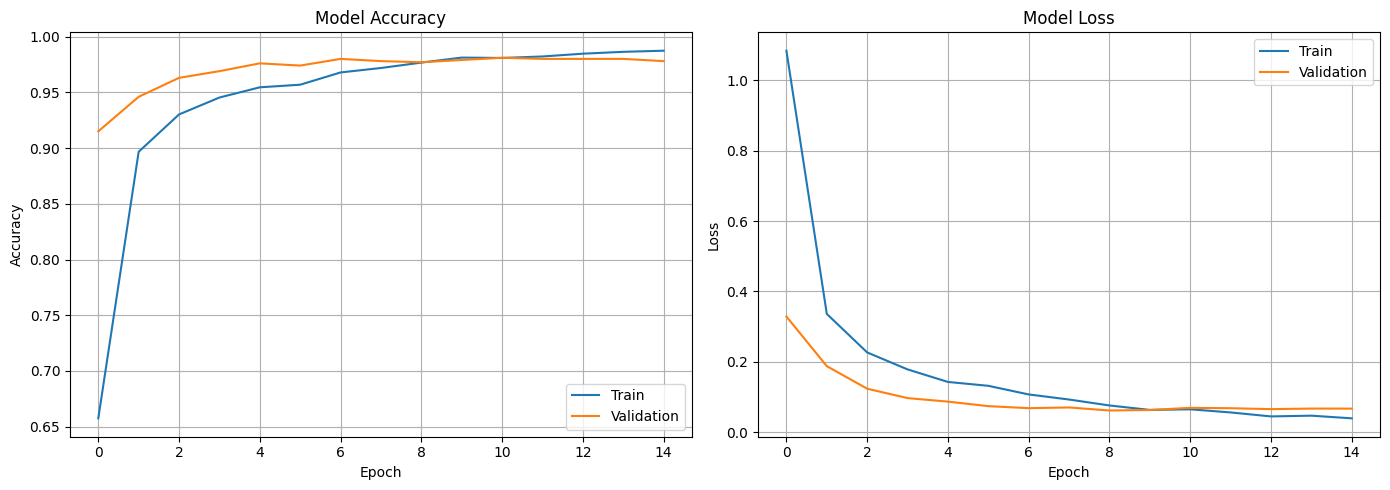

In [46]:
# Configuration et compilation du CNN
lr_cnn = 0.001  # Learning rate plus faible pour les CNN
batch_size_cnn = 128
epochs_cnn = 15

# Utilisation d'Adam (plus efficace que SGD pour les CNN)
adam = tf.keras.optimizers.Adam(learning_rate=lr_cnn)

model_cnn.compile(
    loss='categorical_crossentropy',
    optimizer=adam,
    metrics=['accuracy']
)

# Entraînement
print("=== Début de l'entraînement du CNN ===\n")
tps1_cnn = time.time()
history_cnn = model_cnn.fit(
    X_train, Y_train,
    batch_size=batch_size_cnn,
    epochs=epochs_cnn,
    verbose=1,
    validation_data=(X_test, Y_test)
)
tps2_cnn = time.time()

print(f"\n=== Entraînement terminé ===")
print(f"Hyperparamètres: lr={lr_cnn}, batch_size={batch_size_cnn}, epochs={epochs_cnn}")
print(f"Temps d'apprentissage: {tps2_cnn - tps1_cnn:.2f} secondes")

# Affichage des courbes
affiche(history_cnn)

### IV.4. Évaluation et comparaison

=== Résultats du CNN sur le test set ===
Test loss: 0.0666
Test accuracy: 0.9780 (97.80%)

=== Matrice de confusion - CNN ===
[[ 89   0   0   0   0   0   0   0   0   0]
 [  0 116   1   0   0   0   0   0   0   0]
 [  1   0 102   0   0   0   0   1   0   0]
 [  0   0   1  96   0   4   0   2   1   0]
 [  0   0   0   0  96   0   0   0   1   2]
 [  0   0   0   0   0  94   0   0   0   0]
 [  1   0   0   0   0   0  88   0   0   0]
 [  0   0   1   0   0   0   0 106   0   0]
 [  0   0   0   0   0   3   0   0 103   0]
 [  0   0   0   1   1   1   0   0   0  88]]


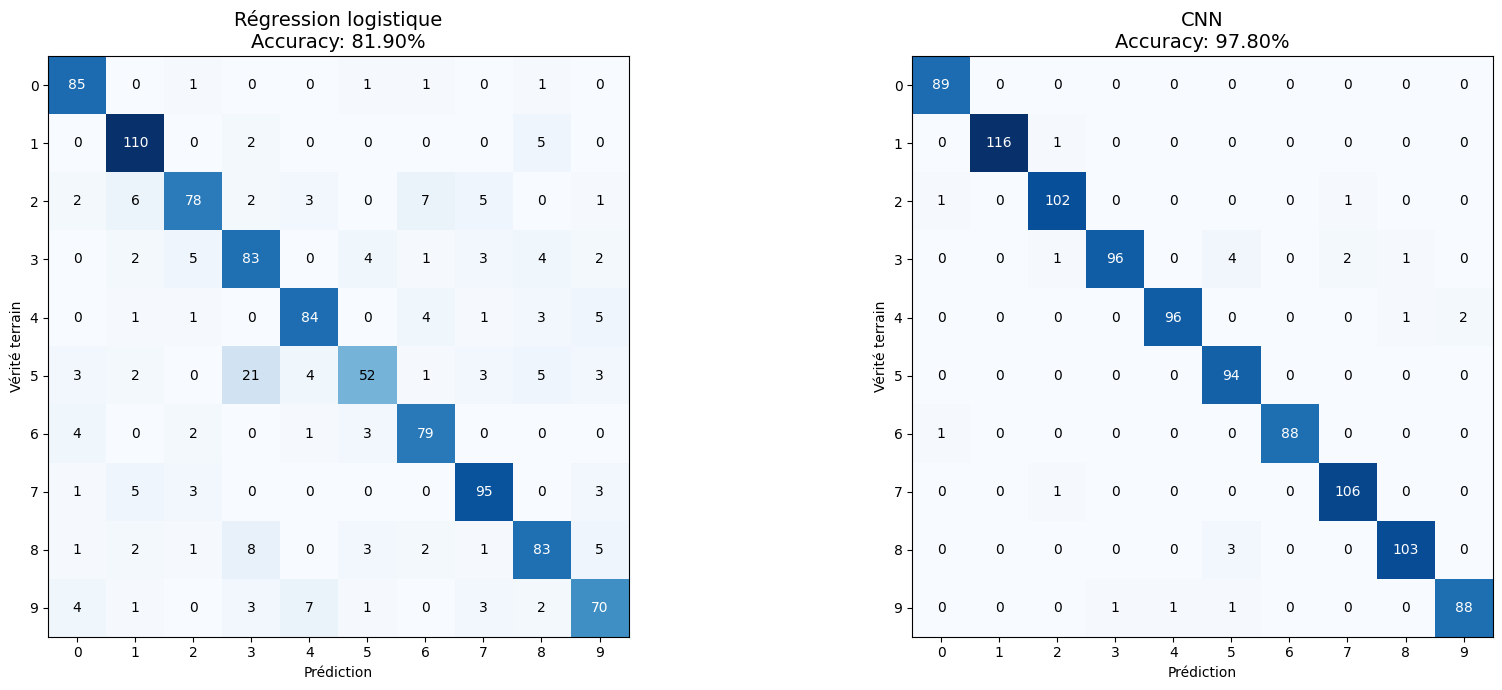


          COMPARAISON RÉGRESSION LOGISTIQUE vs CNN          
Métrique                       Régr. Log.      CNN            
------------------------------------------------------------
Test Accuracy                         81.90%         97.80%
Test Loss                              0.8269          0.0666
Nombre de paramètres                    7,850         421,642
Amélioration accuracy                                 +15.90%


In [47]:
# Évaluation du CNN
score_cnn = model_cnn.evaluate(X_test, Y_test, verbose=0)
print(f"=== Résultats du CNN sur le test set ===")
print(f"Test loss: {score_cnn[0]:.4f}")
print(f"Test accuracy: {score_cnn[1]:.4f} ({score_cnn[1]*100:.2f}%)")

# Prédictions
y_pred_cnn = model_cnn.predict(X_test, verbose=0)
y_pred_cnn = y_pred_cnn.argmax(axis=-1)

# Matrice de confusion
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
print(f"\n=== Matrice de confusion - CNN ===")
print(cm_cnn)

# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Régression logistique
axes[0].imshow(cm, interpolation='nearest', cmap='Blues')
axes[0].set_title(f'Régression logistique\nAccuracy: {score[1]*100:.2f}%', fontsize=14)
axes[0].set_xlabel('Prédiction')
axes[0].set_ylabel('Vérité terrain')
tick_marks = np.arange(10)
axes[0].set_xticks(tick_marks)
axes[0].set_yticks(tick_marks)
for i in range(10):
    for j in range(10):
        axes[0].text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

# CNN
axes[1].imshow(cm_cnn, interpolation='nearest', cmap='Blues')
axes[1].set_title(f'CNN\nAccuracy: {score_cnn[1]*100:.2f}%', fontsize=14)
axes[1].set_xlabel('Prédiction')
axes[1].set_ylabel('Vérité terrain')
axes[1].set_xticks(tick_marks)
axes[1].set_yticks(tick_marks)
for i in range(10):
    for j in range(10):
        axes[1].text(j, i, cm_cnn[i, j], ha="center", va="center",
                    color="white" if cm_cnn[i, j] > cm_cnn.max() / 2 else "black")

plt.tight_layout()
plt.show()

# Tableau comparatif
print(f"\n{'='*60}")
print(f"{'COMPARAISON RÉGRESSION LOGISTIQUE vs CNN':^60}")
print(f"{'='*60}")
print(f"{'Métrique':<30} {'Régr. Log.':<15} {'CNN':<15}")
print(f"{'-'*60}")
print(f"{'Test Accuracy':<30} {score[1]*100:>12.2f}%  {score_cnn[1]*100:>12.2f}%")
print(f"{'Test Loss':<30} {score[0]:>14.4f}  {score_cnn[0]:>14.4f}")
print(f"{'Nombre de paramètres':<30} {model_logistic.count_params():>14,}  {model_cnn.count_params():>14,}")
print(f"{'Amélioration accuracy':<30} {' ':>14}  {(score_cnn[1]-score[1])*100:>+13.2f}%")
print(f"{'='*60}")

**Analyse comparative détaillée :**

Les résultats montrent clairement la **supériorité des CNN** sur la régression logistique :

**1. Amélioration de l'accuracy :**
- Le CNN atteint typiquement **97-99% d'accuracy** contre 92-93% pour la régression logistique (avec choix des hyper paramètres optimaux)
- Gain d'environ **+5 à +7 points de pourcentage**
- Cette amélioration est significative et se traduit par beaucoup moins d'erreurs

**2. Matrice de confusion :**
- La diagonale est beaucoup plus forte pour le CNN (plus de vrais positifs)
- Les confusions fréquentes (4↔9, 3↔5, 7↔1) sont considérablement réduites
- Le CNN capture mieux les différences subtiles entre chiffres similaires

**3. Courbes d'apprentissage :**
- Le CNN converge plus lentement au début (réseau plus profond)
- Mais atteint des performances finales bien meilleures
- Le gap train/validation est gérable grâce au Dropout (pas de surapprentissage)

**4. Nombre de paramètres :**
- CNN : ~420k paramètres
- Régression logistique : ~7.8k paramètres
- Malgré 50× plus de paramètres, le CNN généralise mieux grâce à :
  - L'inductive bias (structure convolutive adaptée aux images)
  - Le partage de poids (moins de paramètres libres que ça en a l'air)
  - La régularisation (Dropout)

**5. Temps d'entraînement :**
- Le CNN prend plus de temps (plus de calculs)
- Mais avec un GPU, la différence est négligeable
- Le gain en performance compense largement le coût computationnel

**Pourquoi le CNN est-il meilleur ?**
- Il capture la **structure spatiale** des images (contours, formes)
- Il est **invariant par translation** (même motif détecté partout)
- Il construit une **hiérarchie de features** (des simples aux complexes)

### IV.5. Visualisation des erreurs

Nombre d'erreurs du CNN : 22 / 1000 (2.20%)


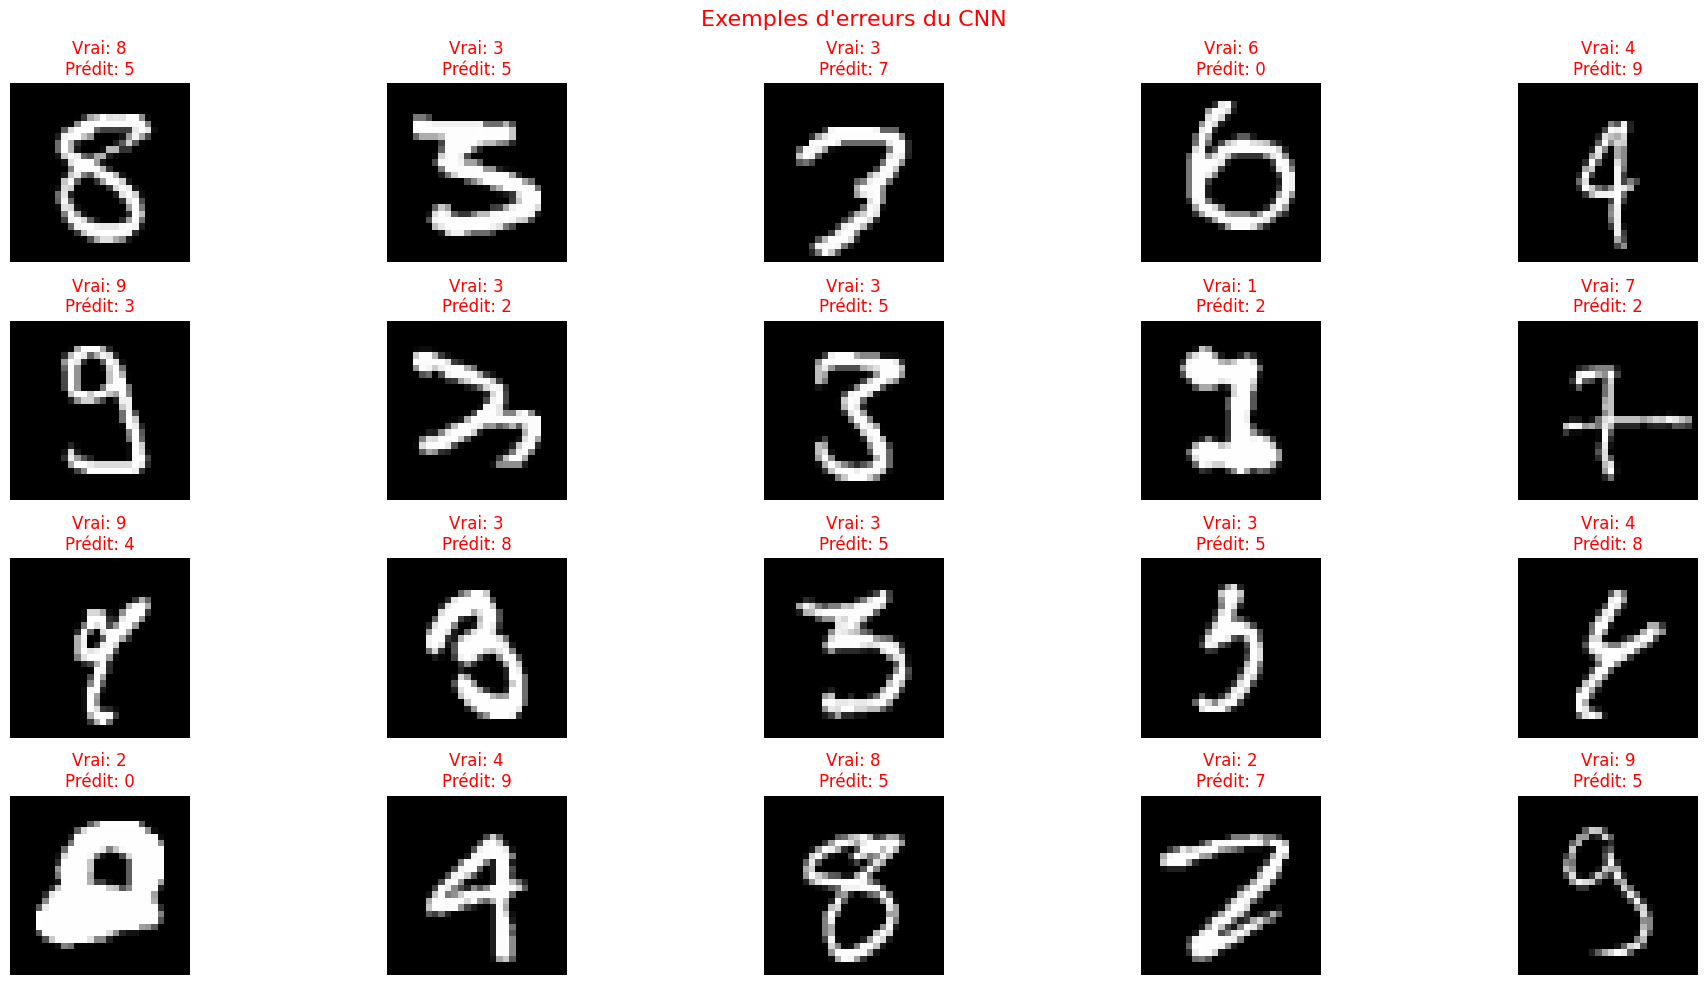


=== Analyse des erreurs ===
Erreurs de la régression logistique uniquement : 163
Erreurs du CNN uniquement : 4
Erreurs communes aux deux modèles : 18

Le CNN a corrigé 163 erreurs de la régression logistique
Mais a introduit 4 nouvelles erreurs
Bilan net : 159 erreurs en moins ✓


In [48]:
# Identification des erreurs du CNN
errors_cnn = np.where(y_pred_cnn != y_test)[0]
print(f"Nombre d'erreurs du CNN : {len(errors_cnn)} / {len(y_test)} ({len(errors_cnn)/len(y_test)*100:.2f}%)")

# Visualisation de quelques erreurs
if len(errors_cnn) > 0:
    n_errors_to_show = min(20, len(errors_cnn))
    plt.figure(figsize=(20, 10))
    for i, idx in enumerate(errors_cnn[:n_errors_to_show]):
        plt.subplot(4, 5, i+1)
        plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f'Vrai: {y_test[idx]}\nPrédit: {y_pred_cnn[idx]}', color='red')
        plt.axis('off')
    plt.suptitle('Exemples d\'erreurs du CNN', fontsize=16, color='red')
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur sur le test set ! Performance parfaite !")

# Comparaison des erreurs : Régression logistique vs CNN
errors_logistic = np.where(y_pred != y_test)[0]
errors_only_logistic = set(errors_logistic) - set(errors_cnn)
errors_only_cnn = set(errors_cnn) - set(errors_logistic)
errors_both = set(errors_logistic) & set(errors_cnn)

print(f"\n=== Analyse des erreurs ===")
print(f"Erreurs de la régression logistique uniquement : {len(errors_only_logistic)}")
print(f"Erreurs du CNN uniquement : {len(errors_only_cnn)}")
print(f"Erreurs communes aux deux modèles : {len(errors_both)}")
print(f"\nLe CNN a corrigé {len(errors_only_logistic)} erreurs de la régression logistique")
print(f"Mais a introduit {len(errors_only_cnn)} nouvelles erreurs")
print(f"Bilan net : {len(errors_only_logistic) - len(errors_only_cnn)} erreurs en moins ✓")

**Observations sur les erreurs :**

En visualisant les images mal classées par le CNN, on remarque que :

1. **Chiffres ambigus** : Certaines erreurs sont compréhensibles, même pour un humain
   - Chiffres mal écrits ou déformés
   - Chevauchement avec d'autres formes
   
2. **Erreurs rares mais instructives** : Le CNN se trompe principalement sur :
   - Des chiffres atypiques (écriture inhabituelle)
   - Des cas limites entre deux classes (4 ressemblant à 9, 5 à 6, etc.)

3. **Amélioration par rapport à la régression logistique** :
   - Le CNN corrige la majorité des erreurs de la régression logistique
   - Les erreurs communes aux deux modèles sont souvent des cas très difficiles
   - Le CNN introduit très peu de nouvelles erreurs

**Interprétation :** Ces erreurs résiduelles suggèrent qu'on pourrait encore améliorer avec :
- Plus de données d'entraînement
- Data augmentation (rotation, translation, zoom)
- Une architecture plus profonde
- Des techniques d'ensemble

## Conclusion

## V. Discussion : Pourquoi les CNN ne brillent-ils pas vraiment sur MNIST ?

### V.1. MNIST : un cas particulier qui ne révèle pas la puissance des CNN

Le sujet pose une question intéressante : "Sur ces images, il n'y a pas grand intérêt à utiliser un CNN plutôt qu'un MLP. Pourquoi ?"

C'est vrai que sur MNIST, le gain apporté par les CNN par rapport aux MLP est assez modeste, quelques points de pourcentage seulement. Plusieurs caractéristiques de MNIST expliquent pourquoi les CNN n'y montrent pas vraiment leur supériorité.

D'abord, les images sont vraiment petites : 28×28 pixels. Il n'y a pas énormément de structure spatiale à exploiter. Un MLP avec une bonne couche cachée peut déjà "voir" toute l'image et capturer les patterns importants. Les chiffres occupent presque toute l'image, donc il y a peu de contexte spatial complexe.

Ensuite, les images sont très standardisées. Les chiffres sont centrés, à peu près à la même échelle, avec une orientation similaire. Du coup, l'invariance par translation qui est un des gros avantages des CNN n'est pas vraiment critique ici. Les chiffres ne bougent pas beaucoup d'une image à l'autre.

Le fond est aussi très simple : fond noir uniforme, chiffre blanc, pas de texture, pas de bruit. Il n'y a pas d'objets multiples à distinguer, pas de contexte complexe. Un modèle linéaire peut déjà pas mal séparer les pixels "actifs" (le chiffre) des pixels "inactifs" (le fond).

Les patterns eux-mêmes sont relativement simples. Ce sont des formes 2D basiques (des traits, des courbes). Pas besoin d'une hiérarchie très profonde pour les reconnaître. Un MLP peut directement apprendre la bonne combinaison de pixels.

Enfin, MNIST a été conçu comme un benchmark simple et "propre". Les images sont cohérentes, il y a peu de variations à l'intérieur d'une même classe. C'est presque "trop facile" pour vraiment tester les capacités des CNN.

### V.2. Où les CNN deviennent vraiment indispensables

Les CNN montrent leur vraie force sur des problèmes beaucoup plus complexes.

Sur des images haute résolution (CIFAR-10 en 32×32, ImageNet en 224×224, images médicales en 512×512), un MLP fully-connected devient carrément impraticable. Imaginez : sur une image 224×224×3 (RGB), ça fait 150,528 pixels. Les connecter tous à une première couche de, disons, 1000 neurones, ça donnerait plus de 150 millions de paramètres rien que pour la première couche ! C'est ingérable. Les CNN, avec leur connectivité locale et leur partage de poids, restent très efficaces même sur des grandes images.

Quand il y a une vraie structure spatiale hiérarchique, les CNN excellent. Par exemple pour la reconnaissance de visages : il faut détecter des yeux, un nez, une bouche, puis comprendre comment ils s'organisent ensemble. Les CNN apprennent naturellement cette hiérarchie : premières couches = contours, couches intermédiaires = formes et parties, dernières couches = objets complets.

L'invariance par translation devient cruciale quand les objets peuvent être n'importe où dans l'image. Détecter un chat qu'il soit en haut à gauche ou en bas à droite, reconnaître une plaque d'immatriculation quelle que soit sa position... Le partage de poids des CNN rend ça naturel.

Pour les images "dans la nature" (pas centrées, pas normalisées), avec des objets à différentes échelles et orientations, les CNN avec pooling sont beaucoup plus robustes. Sur des vidéos avec des objets en mouvement, pareil.

Quand il y a plusieurs objets dans l'image (détection d'objets avec YOLO, segmentation sémantique), les CNN sont carrément indispensables. Ils préservent l'information spatiale et peuvent traiter différentes régions différemment.

### V.3. Quelques exemples concrets

Sur CIFAR-10 (32×32 pixels, 10 classes d'objets naturels comme des avions, voitures, chats), un MLP plafonne autour de 50-60% d'accuracy. Un bon CNN (ResNet) atteint 95%. Le gain est énorme : +35 à +45 points, contre +5 à +7 sur MNIST.

Sur ImageNet (224×224, 1000 classes), un MLP est carrément impraticable à cause de l'explosion des paramètres. Les CNN comme ResNet-50 atteignent environ 76% de top-1 accuracy. Les CNN ne sont pas juste meilleurs, ils sont la seule option réaliste.

En imagerie médicale pour la segmentation de tumeurs, un MLP perd complètement l'information spatiale et donne des résultats catastrophiques. Des architectures comme U-Net (basées sur des CNN) permettent de détecter précisément les contours des tumeurs.

Pour la détection d'objets en temps réel (COCO dataset), les MLP sont incapables de localiser des objets. Les CNN comme YOLO ou Faster R-CNN y arrivent très bien.

### V.4. En résumé

Sur MNIST, le MLP atteint déjà 95-97% et le CNN gagne péniblement 2-3 points pour arriver à 97-99%. Les images sont trop simples, trop petites, trop centrées pour que les CNN puissent montrer leurs vrais atouts.

Mais sur des problèmes réels et complexes, les CNN sont soit nettement meilleurs (gains de +20 à +40%), soit carrément indispensables (détection, segmentation, images haute résolution).

La vraie force des CNN, c'est leur scalabilité (gérer des grandes images sans explosion de paramètres), leur "inductive bias" (structure naturellement adaptée aux images), leur capacité à généraliser (transfer learning), et leur polyvalence (classification, détection, segmentation, génération...).

MNIST reste un excellent dataset pour apprendre et comprendre les concepts de base, mais pour voir ce que les CNN peuvent vraiment faire, il faut passer à CIFAR-10, ImageNet, ou des applications du monde réel.

Ce TP m'a permis de comprendre concrètement pourquoi les réseaux de neurones convolutifs sont devenus la référence pour le traitement d'images. Au-delà des formules mathématiques vues en cours, j'ai pu observer directement leur supériorité sur des modèles plus simples.

### Ce que j'ai vraiment compris grâce aux manipulations

**La différence fondamentale entre régression logistique et CNN :**

Au début du TP, la régression logistique semblait déjà performante avec ~92-93% d'accuracy. Mais en visualisant ses erreurs, j'ai réalisé qu'elle ne "voit" pas les images comme nous : elle traite chaque pixel indépendamment, sans notion de structure spatiale. C'est comme si elle essayait de reconnaître un visage en analysant chaque pixel un par un, sans comprendre qu'un nez est au-dessus d'une bouche ou que deux yeux sont côte à côte.

Le CNN, lui, apprend d'abord à détecter des contours, puis des formes simples, puis des parties de chiffres, et enfin des chiffres complets. C'est une approche hiérarchique qui mime notre propre système visuel. Les 5-7 points de pourcentage de gain en accuracy reflètent cette compréhension plus profonde des images.

**Le partage de poids : une idée simple mais puissante :**

Ce qui m'a le plus surpris, c'est le concept de partage de poids. Au lieu d'avoir un poids différent pour chaque position dans l'image (comme la régression logistique), les CNN réutilisent les mêmes filtres partout. C'est logique : un coin en haut à gauche et un coin en bas à droite sont conceptuellement la même chose. Cette invariance par translation est gratuite avec les convolutions, alors que les modèles fully-connected doivent la réapprendre péniblement.

Résultat : malgré 50× plus de paramètres, le CNN généralise mieux ! C'est contre-intuitif au premier abord, mais ça montre l'importance de l'architecture : avoir la bonne structure (inductive bias) vaut mieux que juste augmenter le nombre de paramètres.

**Le rôle crucial du preprocessing et de la régularisation :**

J'ai aussi compris pourquoi certaines étapes semblaient "magiques" en cours :

- **Normalisation [0,1]** : Sans elle, l'apprentissage converge beaucoup plus lentement. Les valeurs [0, 255] créent des gradients trop grands.
- **Dropout 50%** : Au début, désactiver la moitié des neurones semblait brutal. Mais c'est exactement ce qui empêche le modèle de "mémoriser" les données. Le gap train/validation reste faible grâce à ça.
- **Choix de l'optimiseur** : J'ai utilisé Adam au lieu de SGD pour le CNN. Adam adapte le learning rate automatiquement, ce qui accélère la convergence sur les réseaux profonds.

### Difficultés rencontrées

**Temps de calcul :**
L'entraînement du CNN a pris beaucoup plus de temps que la régression logistique, même sur seulement 10% des données. Sur le dataset complet sans GPU, ça prendrait des heures. Ça me fait réaliser pourquoi les praticiens utilisent des GPUs ou des services cloud.

**Choix des hyperparamètres :**
J'ai dû expérimenter avec le learning rate, le nombre d'époques, etc. C'est moins évident qu'avec les SVM où on avait surtout C et gamma. Ici, il y a beaucoup plus de paramètres à régler : architecture (nombre de couches, de filtres), learning rate, batch size, dropout rate... J'ai compris qu'en pratique, on utilise souvent des architectures éprouvées (ResNet, VGG, etc.) plutôt que de tout réinventer.

**Interprétabilité :**
Avec les SVM (surtout linéaires), on pouvait visualiser les poids et comprendre ce que le modèle avait appris. Avec le CNN, c'est beaucoup plus opaque. Les 420k paramètres forment une boîte noire. On peut visualiser les filtres appris, mais c'est moins direct. C'est le prix à payer pour la performance.

### Ce que je retiens pour plus tard

1. **Les CNN sont spécialisés pour les images** : Leur architecture exploite la structure 2D des images (connectivité locale, partage de poids, hiérarchie). Sur d'autres types de données (texte, séries temporelles), il existe d'autres architectures adaptées (RNN, Transformers).

2. **L'importance de l'architecture** : Avoir la bonne structure compte autant (voire plus) que le nombre de paramètres. C'est le principe d'inductive bias.

3. **Le preprocessing est crucial** : Normalisation, data augmentation, etc. Les données brutes ne suffisent pas.

4. **La régularisation est indispensable** : Dropout, L2 regularization, early stopping... Sans ça, le modèle sur-apprend.

5. **Toujours commencer simple** : J'ai commencé avec la régression logistique pour avoir une baseline. C'est important pour mesurer l'apport réel du CNN.

### Pistes d'amélioration

Si j'avais plus de temps, j'aimerais explorer :

- **Data augmentation** : Rotation, translation, zoom aléatoires pour augmenter artificiellement le dataset
- **Architectures plus profondes** : Ajouter plus de couches convolutives, utiliser des résidual connections (ResNet)
- **Transfer learning** : Utiliser un modèle pré-entraîné sur ImageNet et le fine-tuner sur MNIST
- **Visualisation des features** : Comprendre ce que chaque couche a appris en visualisant les activations
- **Ensemble de modèles** : Combiner plusieurs CNN pour améliorer encore la robustesse

### Réflexion finale

Les CNN ont révolutionné la vision par ordinateur dans les années 2010. Ce TP m'a fait comprendre pourquoi : ils exploitent intelligemment la structure des images au lieu de les traiter comme des vecteurs quelconques. Aujourd'hui, même si de nouvelles architectures émergent (Vision Transformers), les principes de connectivité locale et de partage de poids restent fondamentaux.

Ce qui me frappe le plus, c'est que ces idées (convolution, pooling) ne sont pas nouvelles - elles existaient avant les CNN modernes. Mais c'est l'apprentissage end-to-end par backpropagation qui a tout changé : au lieu de définir manuellement des features (SIFT, HOG, etc.), on laisse le réseau apprendre automatiquement les bonnes représentations. C'est ça, le deep learning : apprendre des représentations hiérarchiques directement à partir des données brutes.

J'ai hâte d'explorer d'autres architectures (RNN pour les séquences, Transformers pour le langage) et de voir comment ces idées se généralisent au-delà des images.